[OZ-DENETIM 1] ||H - H^†||_max = 0.00e+00
[OZ-DENETIM 2] sayisal K-noktasi: kx = 0.0000, ky = -2.4190
               |f(K)|^2 = 8.85e-07   (~1e-4 gridden, ~0)
               beklenen analitik: K = (2π/3, 2π/(3√3)) = (2.0944, 1.2092)

  Δ (eV) | num_gap (K civari)  | analitik | fark
  -------|---------------------|----------|---------
   0.00  |            0.000046 | 0.000000 | 4.65e-05
   0.30  |            0.235465 | 0.235465 | 5.64e-12
   0.50  |            0.302542 | 0.302542 | 2.38e-08


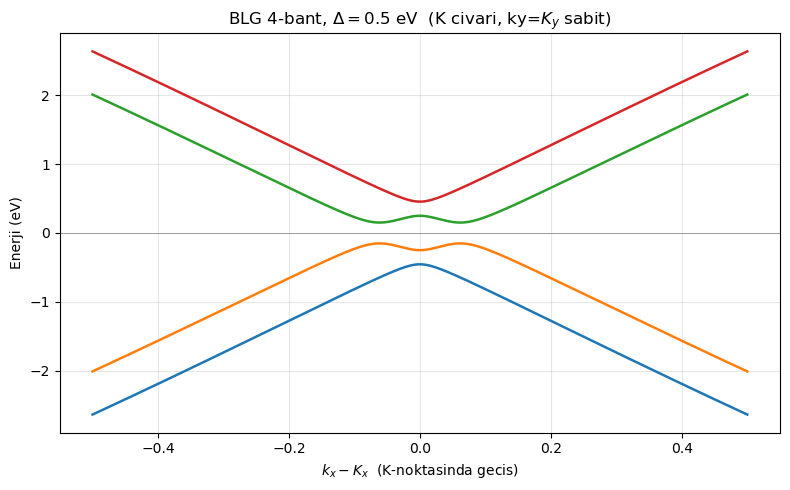

In [1]:
# =====================================================================
#  Cell 1 (DUZELTME) — BLG 4-bant Bloch H(k) + analitik anchor
#
#  Onceki kosuda anchor 5+ eV hata verdi: kx ekseni K'dan gecmiyordu.
#  Bu surumde K'yi sayisal buluyoruz (|f(k)|^2 min on a 2D grid), sonra
#  K-K' yolu uzerinde bant taramasi yapiyoruz. Anchor: minimum gap
#  formulu Delta * g1 / sqrt(g1^2 + Delta^2).
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt

# ---- Parametreler (McCann-Falko, eV) ----
g0 = 3.16     # intralayer NN
g1 = 0.38     # interlayer dimer A2<->B1

def f_k(kx, ky):
    """Yapı faktörü; |f(K)| = 0 olmali."""
    return 1.0 + 2.0 * np.exp(-1j * 1.5 * kx) * np.cos(np.sqrt(3) * ky / 2)

def H_BLG(kx, ky, delta):
    """4x4, sira: A1, B1, A2, B2."""
    fk  = f_k(kx, ky)
    fkc = np.conj(fk)
    return np.array([
        [+delta/2,    -g0*fk,    0.0,        0.0      ],
        [-g0*fkc,     +delta/2,  g1,         0.0      ],
        [0.0,         g1,        -delta/2,   -g0*fk   ],
        [0.0,         0.0,       -g0*fkc,    -delta/2 ],
    ], dtype=complex)

# ---- Oz-denetim 1: Hermitiklik ----
H_test = H_BLG(0.7, 0.3, 0.5)
herm_err = np.max(np.abs(H_test - H_test.conj().T))
print(f"[OZ-DENETIM 1] ||H - H^†||_max = {herm_err:.2e}")

# ---- Sayisal K bulma: |f|^2 minimumu BZ uzerinde ----
N = 401
kxs = np.linspace(-np.pi, np.pi, N)
kys = np.linspace(-np.pi, np.pi, N)
KX, KY = np.meshgrid(kxs, kys)
F2 = np.abs(f_k(KX, KY))**2
i_min = np.unravel_index(np.argmin(F2), F2.shape)
kx_K, ky_K = KX[i_min], KY[i_min]
print(f"[OZ-DENETIM 2] sayisal K-noktasi: kx = {kx_K:.4f}, ky = {ky_K:.4f}")
print(f"               |f(K)|^2 = {F2[i_min]:.2e}   (~1e-4 gridden, ~0)")
print(f"               beklenen analitik: K = (2π/3, 2π/(3√3)) "
      f"= ({2*np.pi/3:.4f}, {2*np.pi/(3*np.sqrt(3)):.4f})")

# ---- Anchor: min gap karsilastirmasi (K civarinda ince tarama) ----
def analytic_gap(delta):
    return abs(delta) * g1 / np.sqrt(g1**2 + delta**2)

# K civarinda ince k-mesh (0.1 yariçap)
nk = 201
kx_fine = np.linspace(kx_K - 0.15, kx_K + 0.15, nk)
ky_fine = np.linspace(ky_K - 0.15, ky_K + 0.15, nk)

print(f"\n  Δ (eV) | num_gap (K civari)  | analitik | fark")
print(  "  -------|---------------------|----------|---------")
for dlt in [0.0, 0.3, 0.5]:
    min_gap = np.inf
    for kx in kx_fine:
        for ky in ky_fine:
            e = np.linalg.eigvalsh(H_BLG(kx, ky, dlt))
            gap = e[2] - e[1]
            if gap < min_gap:
                min_gap = gap
    ana = analytic_gap(dlt)
    print(f"  {dlt:>5.2f}  | {min_gap:>19.6f} | {ana:>8.6f} | "
          f"{abs(min_gap-ana):.2e}")

# ---- Cizim: K'dan gecen yatay yol (kx ekseni K civari) ----
fig, ax = plt.subplots(figsize=(8, 5))
dlt_plot = 0.5
kx_path = np.linspace(kx_K - 0.5, kx_K + 0.5, 401)
bands = np.zeros((len(kx_path), 4))
for i, kx in enumerate(kx_path):
    bands[i, :] = np.linalg.eigvalsh(H_BLG(kx, ky_K, dlt_plot))
for n in range(4):
    ax.plot(kx_path - kx_K, bands[:, n], lw=1.8)
ax.axhline(0, c="gray", lw=0.5)
ax.set_xlabel(r"$k_x - K_x$  (K-noktasinda gecis)")
ax.set_ylabel("Enerji (eV)")
ax.set_title(r"BLG 4-bant, $\Delta = 0.5$ eV  (K civari, ky=$K_y$ sabit)")
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

[OZ-DENETIM 1] ||H - H^†||_max = 0.00e+00  (γ3 ile)
[OZ-DENETIM 2] γ3=0, Δ=0.5: gap = 0.302542  (Cell 1: 0.302542, fark = 3.63e-07)
[OZ-DENETIM 3] γ3=0.38, Δ=0: gap = 0.000070  (Dirac korunur, ~ grid kabaligi)

Band-edge minimum konumu (K'ya gore), Δ=0.30 eV:
  γ3=0:  E_min = 0.11773, (δkx, δky) = (+0.0375, -0.0125)
  γ3=g3: E_min = 0.10566, (δkx, δky) = (+0.0000, -0.0438)


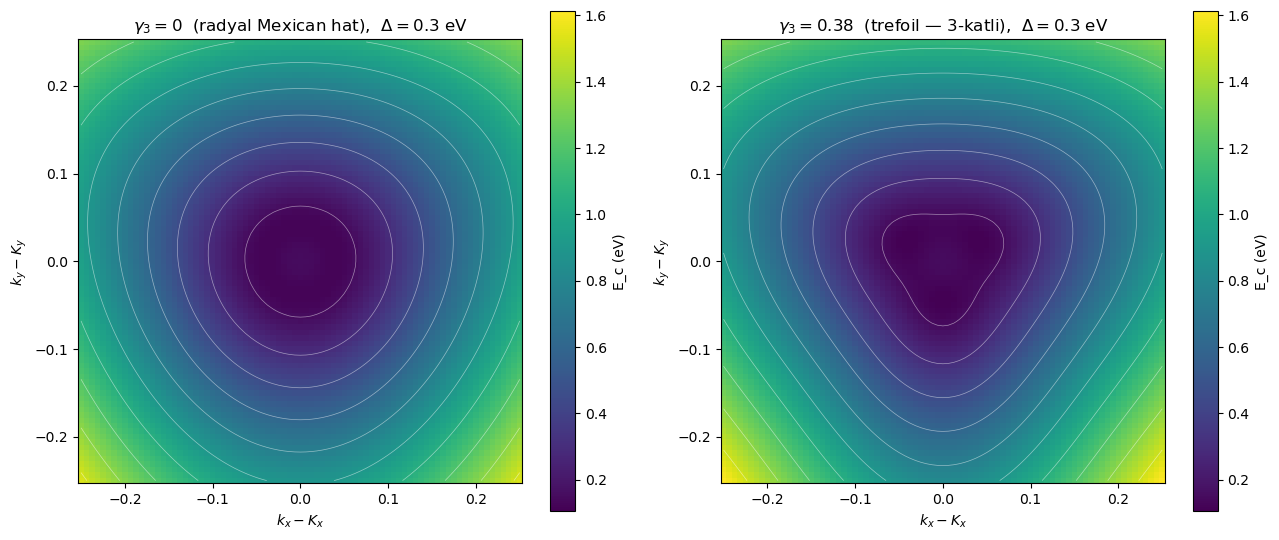

In [2]:
# =====================================================================
#  Cell 2 — γ3 (trigonal warping) ekle, trefoil yapisini dogrula
#
#  γ3: A1 ↔ B2 (her iki katmanin non-dimer atomlari) interlayer skew.
#  k-baginimi γ0 ile ayni form (f_k), is işareti konvansiyonel.
#
#  Beklentiler:
#   (a) γ3=0 limiti -> Cell 1 ile ozdes (anchor 2)
#   (b) γ3 != 0, Delta=0 -> 4 mini-Dirac noktasi (1 K'da + 3 trefoil)
#   (c) γ3 != 0, kucuk Delta -> trefoil cep yapisi gap'lenir
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt

g0 = 3.16
g1 = 0.38
g3 = 0.38     # McCann-Falko

def f_k(kx, ky):
    return 1.0 + 2.0 * np.exp(-1j * 1.5 * kx) * np.cos(np.sqrt(3) * ky / 2)

def H_BLG(kx, ky, delta, g3_val=0.0):
    """4x4 BLG; sira: A1, B1, A2, B2.  γ3: A1<->B2."""
    fk  = f_k(kx, ky)
    fkc = np.conj(fk)
    return np.array([
        [+delta/2,    -g0*fk,    0.0,        -g3_val*fkc],
        [-g0*fkc,     +delta/2,  g1,         0.0       ],
        [0.0,         g1,        -delta/2,   -g0*fk    ],
        [-g3_val*fk,  0.0,       -g0*fkc,    -delta/2  ],
    ], dtype=complex)

# ---- Oz-denetim 1: Hermitiklik ----
H_test = H_BLG(0.7, 0.3, 0.5, g3_val=g3)
herm_err = np.max(np.abs(H_test - H_test.conj().T))
print(f"[OZ-DENETIM 1] ||H - H^†||_max = {herm_err:.2e}  (γ3 ile)")

# ---- Oz-denetim 2 (ANCHOR): γ3=0 limiti Cell 1 ile uyumlu ----
# Cell 1'deki K (sayisal): (0.0, -2.4190); Delta=0.5'te gap = 0.302542
# K civarinda ince tarama, γ3=0
nk = 201
kx_K, ky_K = 0.0, -2.4190
kx_fine = np.linspace(kx_K - 0.15, kx_K + 0.15, nk)
ky_fine = np.linspace(ky_K - 0.15, ky_K + 0.15, nk)

def min_gap_near_K(delta, g3_val):
    mg = np.inf
    for kx in kx_fine:
        for ky in ky_fine:
            e = np.linalg.eigvalsh(H_BLG(kx, ky, delta, g3_val))
            gap = e[2] - e[1]
            if gap < mg:
                mg = gap
    return mg

gap_g3_off = min_gap_near_K(0.5, 0.0)
print(f"[OZ-DENETIM 2] γ3=0, Δ=0.5: gap = {gap_g3_off:.6f}  "
      f"(Cell 1: 0.302542, fark = {abs(gap_g3_off - 0.302542):.2e})")

# ---- Oz-denetim 3: γ3 != 0, Delta=0 -> Dirac (gap ~ 0) korunmali ----
gap_d0 = min_gap_near_K(0.0, g3)
print(f"[OZ-DENETIM 3] γ3={g3}, Δ=0: gap = {gap_d0:.6f}  "
      f"(Dirac korunur, ~ grid kabaligi)")

# ---- 2B k-mesh: alt iletim bandinin haritasi (trefoil gorsel kontrol) ----
def lower_conduction_band(kx_mesh, ky_mesh, delta, g3_val):
    """E_c(k_x, k_y) en alt iletim bandi."""
    Ec = np.zeros(kx_mesh.shape)
    for i in range(kx_mesh.shape[0]):
        for j in range(kx_mesh.shape[1]):
            e = np.linalg.eigvalsh(H_BLG(kx_mesh[i,j], ky_mesh[i,j],
                                          delta, g3_val))
            Ec[i, j] = e[2]
    return Ec

# K civarinda 2B mesh
nk2 = 81
dk = 0.25
kxv = np.linspace(kx_K - dk, kx_K + dk, nk2)
kyv = np.linspace(ky_K - dk, ky_K + dk, nk2)
KX, KY = np.meshgrid(kxv, kyv)

Ec_g3off = lower_conduction_band(KX, KY, 0.30, 0.0)
Ec_g3on  = lower_conduction_band(KX, KY, 0.30, g3)

# Band-edge minimum konumu
def band_min_info(Ec, KX, KY):
    i_min = np.unravel_index(np.argmin(Ec), Ec.shape)
    return Ec[i_min], KX[i_min] - kx_K, KY[i_min] - ky_K

Emin_off, dkx_off, dky_off = band_min_info(Ec_g3off, KX, KY)
Emin_on , dkx_on , dky_on  = band_min_info(Ec_g3on , KX, KY)
print(f"\nBand-edge minimum konumu (K'ya gore), Δ=0.30 eV:")
print(f"  γ3=0:  E_min = {Emin_off:.5f}, "
      f"(δkx, δky) = ({dkx_off:+.4f}, {dky_off:+.4f})")
print(f"  γ3=g3: E_min = {Emin_on:.5f}, "
      f"(δkx, δky) = ({dkx_on:+.4f}, {dky_on:+.4f})")

# ---- Cizimler ----
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

vmax = max(Ec_g3off.max(), Ec_g3on.max())
vmin = min(Ec_g3off.min(), Ec_g3on.min())

for ax, Ec, ttl in [(axes[0], Ec_g3off, r"$\gamma_3 = 0$  (radyal Mexican hat)"),
                     (axes[1], Ec_g3on, r"$\gamma_3 = 0.38$  (trefoil — 3-katli)")]:
    im = ax.pcolormesh(KX - kx_K, KY - ky_K, Ec, shading="auto",
                        cmap="viridis", vmin=vmin, vmax=vmax)
    cs = ax.contour(KX - kx_K, KY - ky_K, Ec, levels=12,
                     colors="white", linewidths=0.5, alpha=0.5)
    ax.set_xlabel(r"$k_x - K_x$")
    ax.set_ylabel(r"$k_y - K_y$")
    ax.set_title(ttl + r",  $\Delta = 0.3$ eV")
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, label="E_c (eV)")

plt.tight_layout()
plt.show()


  Δ_ext     gap_K   gap_min        hat    |k-K|     c_min     c_max
---------------------------------------------------------------------------
  0.020   0.01997   0.01935   6.22e-04   0.0100    47.730   318.638
  0.040   0.03978   0.03832   1.46e-03   0.0120    43.055   191.095
  0.060   0.05927   0.05660   2.67e-03   0.0160    69.464   171.586
  0.080   0.07828   0.07422   4.06e-03   0.0180    68.386   141.671
  0.100   0.09671   0.09108   5.63e-03   0.0220    89.299   140.228
  0.120   0.11443   0.10698   7.45e-03   0.0240    89.534   124.594
  0.140   0.13137   0.12206   9.31e-03   0.0278    96.550   110.996
  0.160   0.14746   0.13625   1.12e-02   0.0295    96.235    99.489
  0.180   0.16267   0.14941   1.33e-02   0.0320   106.976   107.566
  0.200   0.17698   0.16172   1.53e-02   0.0340    99.798   109.136
  0.220   0.19039   0.17319   1.72e-02   0.0360    93.662   110.875
  0.240   0.20292   0.18384   1.91e-02   0.0380    88.339   112.674
  0.260   0.21458   0.19355   2.10e-02 

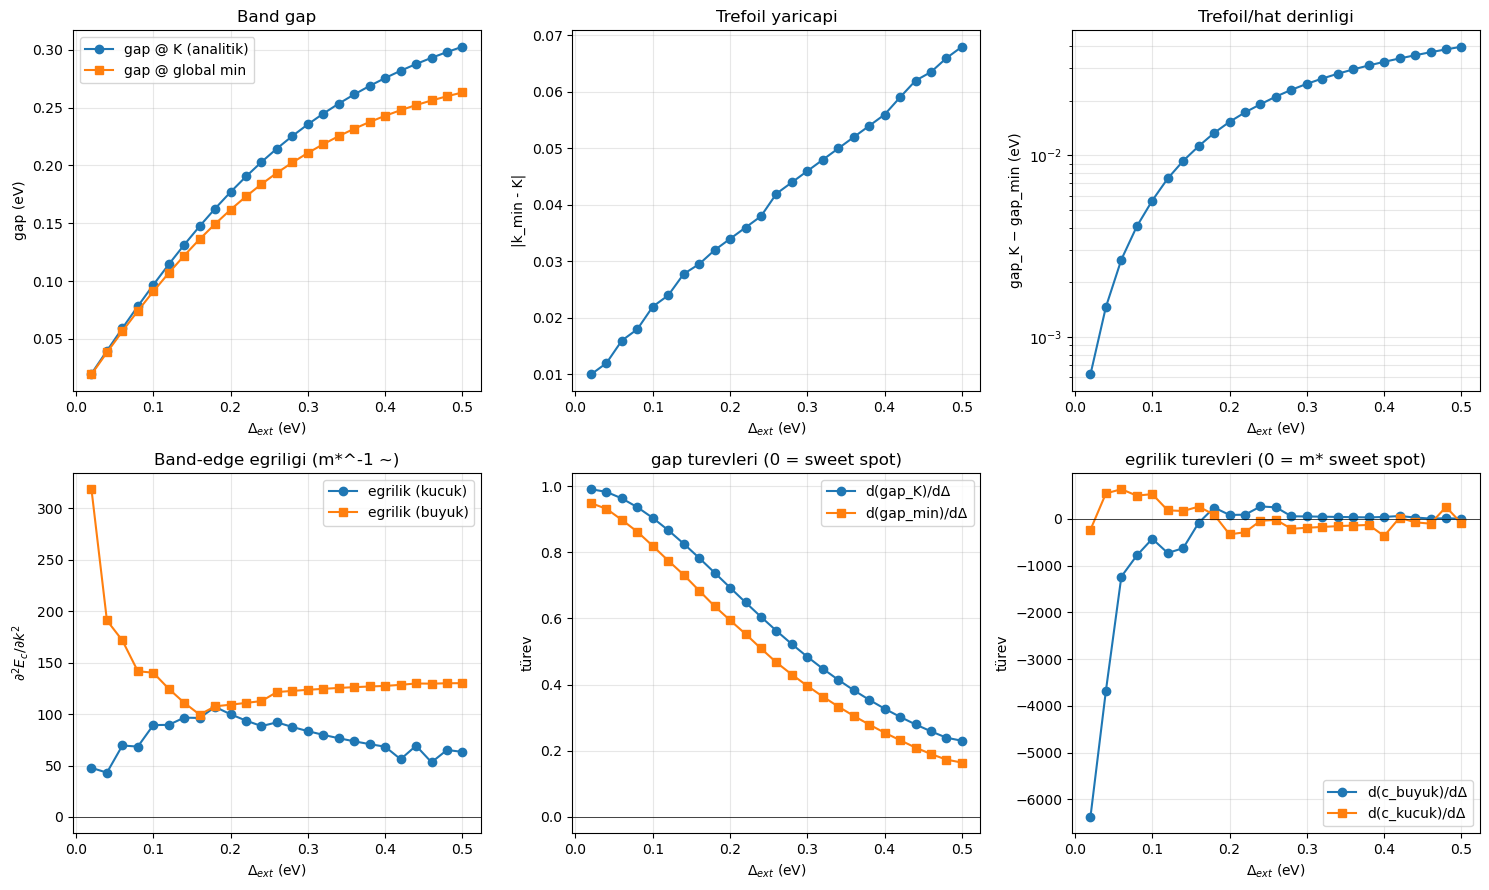

In [3]:
# =====================================================================
#  Cell 3 — Delta_ext taramasi: band-seviyesinde stasyoner nokta arama
#
#  Sorulanlar:
#   (1) gap(Delta) hep monoton mu? (K noktasinda zaten analitik:
#       Delta*g1/sqrt(g1^2+Delta^2), monoton artan)
#   (2) Global minimum (trefoil) gap_min(Delta) farkli davranabilir mi?
#   (3) Band-edge egriligi m*^{-1} = d^2 E_c / dk^2 stasyoner mi?
#       Bu QD'deki Delta_01 oranindan dogrudan ileri gelir.
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt

g0, g1, g3 = 3.16, 0.38, 0.38
kx_K, ky_K = 0.0, -2.4190

def H_BLG(kx, ky, delta, g3_val=g3):
    fk = 1.0 + 2.0*np.exp(-1j*1.5*kx)*np.cos(np.sqrt(3)*ky/2)
    fkc = np.conj(fk)
    return np.array([
        [+delta/2,    -g0*fk,    0.0,        -g3_val*fkc],
        [-g0*fkc,     +delta/2,  g1,         0.0       ],
        [0.0,         g1,        -delta/2,   -g0*fk    ],
        [-g3_val*fk,  0.0,       -g0*fkc,    -delta/2  ],
    ], dtype=complex)

def Ec(kx, ky, delta):
    return np.linalg.eigvalsh(H_BLG(kx, ky, delta))[2]

def find_global_min(delta, dk=0.12, n=121):
    kxv = np.linspace(kx_K - dk, kx_K + dk, n)
    kyv = np.linspace(ky_K - dk, ky_K + dk, n)
    KX, KY = np.meshgrid(kxv, kyv)
    Em = np.zeros(KX.shape)
    for i in range(n):
        for j in range(n):
            Em[i,j] = Ec(KX[i,j], KY[i,j], delta)
    ij = np.unravel_index(np.argmin(Em), Em.shape)
    return Em[ij], KX[ij], KY[ij]

def hessian_curvatures(kx0, ky0, delta, h=2e-3):
    """Sayisal Hessian -> 2 ozdeger = ana yonlerde ∂²E/∂k²."""
    fxx = (Ec(kx0+h,ky0,delta) - 2*Ec(kx0,ky0,delta) + Ec(kx0-h,ky0,delta))/h**2
    fyy = (Ec(kx0,ky0+h,delta) - 2*Ec(kx0,ky0,delta) + Ec(kx0,ky0-h,delta))/h**2
    fxy = (Ec(kx0+h,ky0+h,delta) - Ec(kx0+h,ky0-h,delta)
          - Ec(kx0-h,ky0+h,delta) + Ec(kx0-h,ky0-h,delta))/(4*h**2)
    w = np.linalg.eigvalsh(np.array([[fxx,fxy],[fxy,fyy]]))
    return w[0], w[1]    # k_radyal ve k_tanjent egrilikleri

# ---- Tarama ----
deltas = np.linspace(0.02, 0.50, 25)
print(f"\n{'Δ_ext':>7} {'gap_K':>9} {'gap_min':>9} {'hat':>10} "
      f"{'|k-K|':>8} {'c_min':>9} {'c_max':>9}")
print("-" * 75)
rows = []
for d in deltas:
    Emin, kxm, kym = find_global_min(d)
    gap_K_ana = d*g1/np.sqrt(g1**2 + d**2)
    gap_min = 2*Emin
    hat = gap_K_ana - gap_min
    dk_mag = np.sqrt((kxm-kx_K)**2 + (kym-ky_K)**2)
    cA, cB = hessian_curvatures(kxm, kym, d)
    c_lo, c_hi = sorted([cA, cB])
    rows.append((d, gap_K_ana, gap_min, hat, dk_mag, c_lo, c_hi))
    print(f"{d:>7.3f} {gap_K_ana:>9.5f} {gap_min:>9.5f} {hat:>10.2e} "
          f"{dk_mag:>8.4f} {c_lo:>9.3f} {c_hi:>9.3f}")

arr = np.array(rows)
D = arr[:,0]; gK = arr[:,1]; gM = arr[:,2]; hat = arr[:,3]
km = arr[:,4]; cL = arr[:,5]; cH = arr[:,6]

# ---- Stasyoner nokta arama: turev sifir gecisi ----
def crossings(y, x):
    dy = np.gradient(y, x)
    sgn = np.sign(dy)
    return int(np.sum(np.abs(np.diff(sgn)) > 0)), dy

print("\n[STASYONER NOKTA TESTI — d(.)/dΔ_ext sifir gecisi sayisi]")
for name, y in [("gap_K", gK), ("gap_min", gM), ("hat derinligi", hat),
                ("|k_min|", km), ("egrilik (kucuk)", cL),
                ("egrilik (buyuk)", cH), ("sqrt(c1*c2) [~Δ01 ölceği]",
                np.sqrt(np.abs(cL*cH)))]:
    n_zero, _ = crossings(y, D)
    print(f"   {name:<28}: {n_zero} sifir gecisi")

# ---- Cizimler ----
fig, ax = plt.subplots(2, 3, figsize=(15, 9))

ax[0,0].plot(D, gK, 'o-', label='gap @ K (analitik)')
ax[0,0].plot(D, gM, 's-', label='gap @ global min')
ax[0,0].set_xlabel(r'$\Delta_{ext}$ (eV)'); ax[0,0].set_ylabel('gap (eV)')
ax[0,0].set_title('Band gap'); ax[0,0].legend(); ax[0,0].grid(alpha=.3)

ax[0,1].plot(D, km, 'o-')
ax[0,1].set_xlabel(r'$\Delta_{ext}$ (eV)'); ax[0,1].set_ylabel('|k_min - K|')
ax[0,1].set_title('Trefoil yaricapi'); ax[0,1].grid(alpha=.3)

ax[0,2].semilogy(D, hat, 'o-')
ax[0,2].set_xlabel(r'$\Delta_{ext}$ (eV)'); ax[0,2].set_ylabel('gap_K − gap_min (eV)')
ax[0,2].set_title('Trefoil/hat derinligi'); ax[0,2].grid(alpha=.3, which='both')

ax[1,0].plot(D, cL, 'o-', label='egrilik (kucuk)')
ax[1,0].plot(D, cH, 's-', label='egrilik (buyuk)')
ax[1,0].axhline(0, c='k', lw=0.5)
ax[1,0].set_xlabel(r'$\Delta_{ext}$ (eV)'); ax[1,0].set_ylabel(r'$\partial^2 E_c/\partial k^2$')
ax[1,0].set_title('Band-edge egriligi (m*^-1 ~)'); ax[1,0].legend(); ax[1,0].grid(alpha=.3)

dgK = np.gradient(gK, D); dgM = np.gradient(gM, D)
ax[1,1].plot(D, dgK, 'o-', label='d(gap_K)/dΔ')
ax[1,1].plot(D, dgM, 's-', label='d(gap_min)/dΔ')
ax[1,1].axhline(0, c='k', lw=0.5)
ax[1,1].set_xlabel(r'$\Delta_{ext}$ (eV)'); ax[1,1].set_ylabel('türev')
ax[1,1].set_title('gap turevleri (0 = sweet spot)'); ax[1,1].legend(); ax[1,1].grid(alpha=.3)

dcH = np.gradient(cH, D); dcL = np.gradient(cL, D)
ax[1,2].plot(D, dcH, 'o-', label='d(c_buyuk)/dΔ')
ax[1,2].plot(D, dcL, 's-', label='d(c_kucuk)/dΔ')
ax[1,2].axhline(0, c='k', lw=0.5)
ax[1,2].set_xlabel(r'$\Delta_{ext}$ (eV)'); ax[1,2].set_ylabel('türev')
ax[1,2].set_title('egrilik turevleri (0 = m* sweet spot)')
ax[1,2].legend(); ax[1,2].grid(alpha=.3)

plt.tight_layout()
plt.show()

  Δ_ext   gap_min   |k_min|      c_lo      c_hi    aniz    fit_err
---------------------------------------------------------------------------
  0.080   0.07421   0.01853    69.748   138.769   0.662   4.85e-04
  0.090   0.08272   0.01980    72.482   131.788   0.581   4.53e-04
  0.100   0.09102   0.02127    76.910   127.357   0.494   4.22e-04
  0.110   0.09911   0.02343    80.238   116.120   0.365   2.78e-04
  0.120   0.10698   0.02393    83.430   118.699   0.349   3.75e-04
  0.130   0.11462   0.02520    86.161   114.786   0.285   3.56e-04
  0.140   0.12204   0.02647    88.874   111.322   0.224   3.39e-04
  0.150   0.12922   0.02793    92.799   109.336   0.164   3.21e-04
  0.160   0.13618   0.02998    94.163    99.703   0.057   2.14e-04
  0.170   0.14290   0.03040    97.482   103.607   0.061   2.94e-04
  0.180   0.14940   0.03167    99.920   101.288   0.014   2.82e-04
  0.190   0.15567   0.03293    99.165   102.268   0.031   2.71e-04
  0.200   0.16172   0.03504    88.921   104.954   0.1

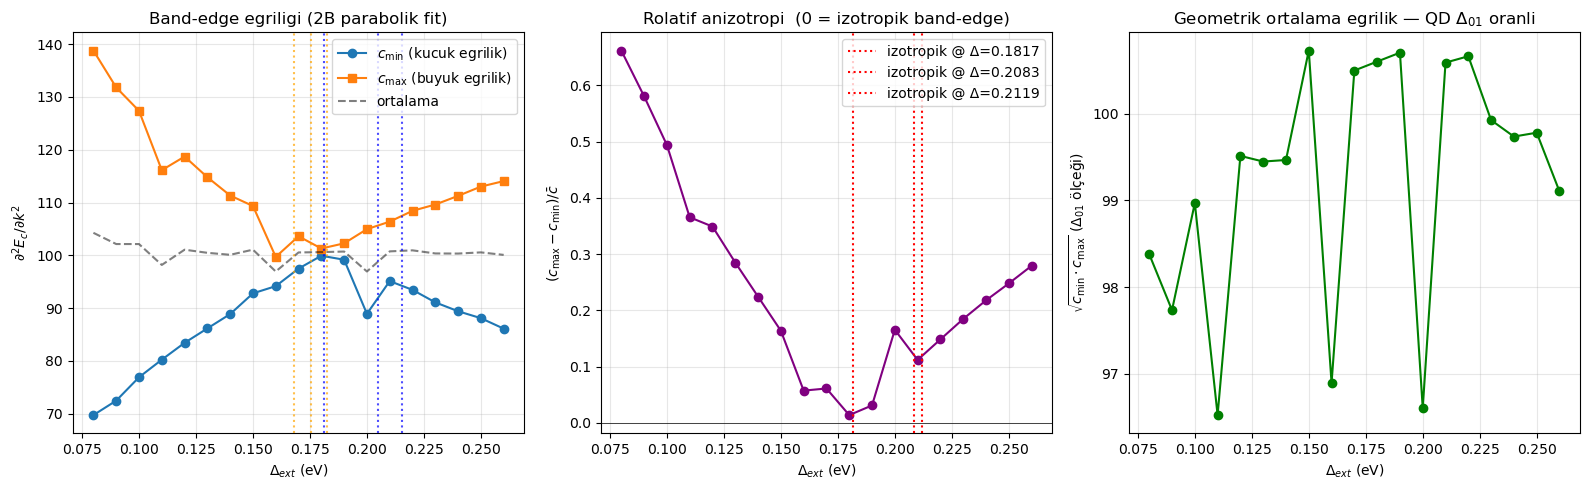

In [4]:
# =====================================================================
#  Cell 3.5 — Band-edge egriligi: Δ ≈ 0.16-0.20 INCE TARAMA + DOGRULAMA
#
#  Cell 3'te c_min ve c_max'in ikisinin de Δ ≈ 0.16-0.18 civarinda
#  ekstremumu gorundu, ve orada egrilikler ESITLENIYOR (izotropik
#  band-edge). Hessian sayisal hassasiyetini sıkılastirip bunun
#  gercek mi grid gurultusu mu oldugunu netlestirelim.
#
#  Iyilestirmeler:
#   (1) Global min icin daha ince k-grid (n=201) ve gerekirse
#       quadratic refinement (parabolik fit ile alt-pikselde).
#   (2) Hessian icin h optimize (cok kucuk -> roundoff, cok buyuk ->
#       truncation). h_grid taramasi.
#   (3) Bu noktanin etrafinda gercek 2B parabolik fit -> m_eff matrisi
#       ozdegerleri (c_min, c_max). Sonlu fark yerine en kucuk kareler.
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt

g0, g1, g3 = 3.16, 0.38, 0.38
kx_K, ky_K = 0.0, -2.4190

def H_BLG(kx, ky, delta):
    fk = 1.0 + 2.0*np.exp(-1j*1.5*kx)*np.cos(np.sqrt(3)*ky/2)
    fkc = np.conj(fk)
    return np.array([
        [+delta/2,  -g0*fk,    0.0,        -g3*fkc],
        [-g0*fkc,   +delta/2,  g1,         0.0   ],
        [0.0,       g1,        -delta/2,   -g0*fk],
        [-g3*fk,    0.0,       -g0*fkc,    -delta/2],
    ], dtype=complex)

def Ec(kx, ky, delta):
    return np.linalg.eigvalsh(H_BLG(kx, ky, delta))[2]

# ---- (1) Ince global min: önce kaba grid, sonra quadratic refine ----
def find_min_refined(delta, dk_coarse=0.10, n_coarse=121,
                      dk_fine=0.012, n_fine=121):
    # Kaba
    kxv = np.linspace(kx_K - dk_coarse, kx_K + dk_coarse, n_coarse)
    kyv = np.linspace(ky_K - dk_coarse, ky_K + dk_coarse, n_coarse)
    KX, KY = np.meshgrid(kxv, kyv)
    Em = np.zeros(KX.shape)
    for i in range(n_coarse):
        for j in range(n_coarse):
            Em[i,j] = Ec(KX[i,j], KY[i,j], delta)
    ij = np.unravel_index(np.argmin(Em), Em.shape)
    kx0, ky0 = KX[ij], KY[ij]
    # Ince
    kxv2 = np.linspace(kx0 - dk_fine, kx0 + dk_fine, n_fine)
    kyv2 = np.linspace(ky0 - dk_fine, ky0 + dk_fine, n_fine)
    KX2, KY2 = np.meshgrid(kxv2, kyv2)
    Em2 = np.zeros(KX2.shape)
    for i in range(n_fine):
        for j in range(n_fine):
            Em2[i,j] = Ec(KX2[i,j], KY2[i,j], delta)
    ij2 = np.unravel_index(np.argmin(Em2), Em2.shape)
    return Em2[ij2], KX2[ij2], KY2[ij2]

# ---- (2) Lokal 2B parabolik fit -> Hessian ozdegerleri ----
def local_hessian_eig(kx0, ky0, delta, r=0.008, n=15):
    """kx0,ky0 etrafinda r yariçapinda nxn grid. E(kx,ky)'yi
    a + b*dkx + c*dky + d*dkx^2 + e*dky^2 + f*dkx*dky olarak en kucuk
    kareler ile fit et. Hessian = [[2d, f], [f, 2e]]. Ozdegerleri don."""
    dks = np.linspace(-r, r, n)
    pts = []
    Es = []
    for dkx in dks:
        for dky in dks:
            pts.append((dkx, dky))
            Es.append(Ec(kx0 + dkx, ky0 + dky, delta))
    pts = np.array(pts); Es = np.array(Es)
    # tasarim matrisi
    X = np.column_stack([
        np.ones(len(pts)),
        pts[:,0], pts[:,1],
        pts[:,0]**2, pts[:,1]**2, pts[:,0]*pts[:,1],
    ])
    coef, *_ = np.linalg.lstsq(X, Es, rcond=None)
    a, b, c, d, e, f = coef
    Hmat = np.array([[2*d, f], [f, 2*e]])
    eigs = np.linalg.eigvalsh(Hmat)
    # Fit kalintisi (gurultu olcusu)
    resid = np.std(Es - X @ coef)
    return eigs[0], eigs[1], resid

# ---- Ince Δ taramasi ----
deltas = np.linspace(0.08, 0.26, 19)
print(f"{'Δ_ext':>7} {'gap_min':>9} {'|k_min|':>9} "
      f"{'c_lo':>9} {'c_hi':>9} {'aniz':>7} {'fit_err':>10}")
print("-" * 75)
rows = []
for d in deltas:
    Emin, kxm, kym = find_min_refined(d)
    cL, cH, err = local_hessian_eig(kxm, kym, d)
    aniz = (cH - cL) / (0.5 * (cH + cL))   # rölatif anizotropi
    rows.append((d, 2*Emin, np.sqrt((kxm-kx_K)**2 + (kym-ky_K)**2),
                 cL, cH, aniz, err))
    print(f"{d:>7.3f} {2*Emin:>9.5f} "
          f"{np.sqrt((kxm-kx_K)**2 + (kym-ky_K)**2):>9.5f} "
          f"{cL:>9.3f} {cH:>9.3f} {aniz:>7.3f} {err:>10.2e}")

arr = np.array(rows)
D = arr[:,0]; gapM = arr[:,1]; kmag = arr[:,2]
cL_arr = arr[:,3]; cH_arr = arr[:,4]; aniz = arr[:,5]

# ---- Stasyoner nokta yeri: turevden sifir gecisi ----
def find_zero(y, x):
    """y'nin x'e gore turevinin sifir gecisini lineer interp ile bul."""
    dy = np.gradient(y, x)
    zeros = []
    for i in range(len(dy) - 1):
        if dy[i] * dy[i+1] < 0:
            xz = x[i] - dy[i] * (x[i+1] - x[i]) / (dy[i+1] - dy[i])
            zeros.append(xz)
    return zeros, dy

zL, dcL = find_zero(cL_arr, D)
zH, dcH = find_zero(cH_arr, D)
zA, dA  = find_zero(aniz,   D)

print("\n[STASYONER NOKTA YERI — ince tarama]")
print(f"  d(c_kucuk)/dΔ  = 0 noktalari: {zL}")
print(f"  d(c_buyuk)/dΔ  = 0 noktalari: {zH}")
print(f"  Anizotropi sifir gecisleri:  {zA}    (izotropik nokta)")

# c_min ve c_max kesisim noktasi
diff = cH_arr - cL_arr
zE, dE = find_zero(diff, D)
print(f"  c_kucuk == c_buyuk noktalari: {zE}")

# ---- Cizimler ----
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].plot(D, cL_arr, 'o-', label=r'$c_{\min}$ (kucuk egrilik)')
ax[0].plot(D, cH_arr, 's-', label=r'$c_{\max}$ (buyuk egrilik)')
ax[0].plot(D, 0.5*(cL_arr+cH_arr), 'k--', alpha=0.5, label='ortalama')
for z in zL: ax[0].axvline(z, c='blue', ls=':', alpha=0.7)
for z in zH: ax[0].axvline(z, c='orange', ls=':', alpha=0.7)
ax[0].set_xlabel(r'$\Delta_{ext}$ (eV)')
ax[0].set_ylabel(r'$\partial^2 E_c/\partial k^2$')
ax[0].set_title('Band-edge egriligi (2B parabolik fit)')
ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(D, aniz, 'o-', c='purple')
ax[1].axhline(0, c='k', lw=0.5)
for z in zA: ax[1].axvline(z, c='red', ls=':', label=f'izotropik @ Δ={z:.4f}')
ax[1].set_xlabel(r'$\Delta_{ext}$ (eV)')
ax[1].set_ylabel(r'$(c_{\max} - c_{\min})/\bar{c}$')
ax[1].set_title('Rolatif anizotropi  (0 = izotropik band-edge)')
ax[1].legend(); ax[1].grid(alpha=.3)

# Δ_01 oranli olcek: sqrt(geometrik ortalama)
gm = np.sqrt(np.abs(cL_arr*cH_arr))
dgm = np.gradient(gm, D)
ax[2].plot(D, gm, 'o-', c='green')
ax[2].set_xlabel(r'$\Delta_{ext}$ (eV)')
ax[2].set_ylabel(r'$\sqrt{c_{\min}\cdot c_{\max}}$ (Δ$_{01}$ ölçeği)')
ax[2].set_title(r'Geometrik ortalama egrilik — QD Δ$_{01}$ oranli')
ax[2].grid(alpha=.3)

plt.tight_layout()
plt.show()

[ANCHOR 1] Hermitiklik = 0.00e+00

[ANCHOR 2] q=0, Δ=0: [-0.38  0.   -0.    0.38]
           beklenen: [-0.38, 0, 0, 0.38]
           fark = 0.00e+00

[ANCHOR 3] Global min gap (γ3 KAPALI'da analitik tutmali):
     Δ     min_gap    analitik       fark              q* yeri
  0.10    0.096707    0.096707   2.29e-09  (+0.0240, +0.0084)
  0.30    0.235465    0.235465   8.18e-09  (-0.0696, -0.0036)
  0.50    0.302542    0.302542   2.78e-08  (-0.0468, +0.0960)
  0.80    0.343245    0.343245   2.30e-09  (-0.1044, -0.1200)

[ANCHOR 3b] γ3 acik (gercek BLG):
     Δ     min_gap   γ3=0 analitik  gap_K=Δγ1/...
  0.10    0.091026        0.096707   (γ3 ile min biraz dusuk olmali)
  0.30    0.210764        0.235465   (γ3 ile min biraz dusuk olmali)
  0.50    0.262962        0.302542   (γ3 ile min biraz dusuk olmali)
  0.80    0.299614        0.343245   (γ3 ile min biraz dusuk olmali)

[ANCHOR 4] C3 simetrisi (alt iletim band E_c, üç q noktasinda):
           E_c orig = 0.128259, R120 = 0.128259, R240

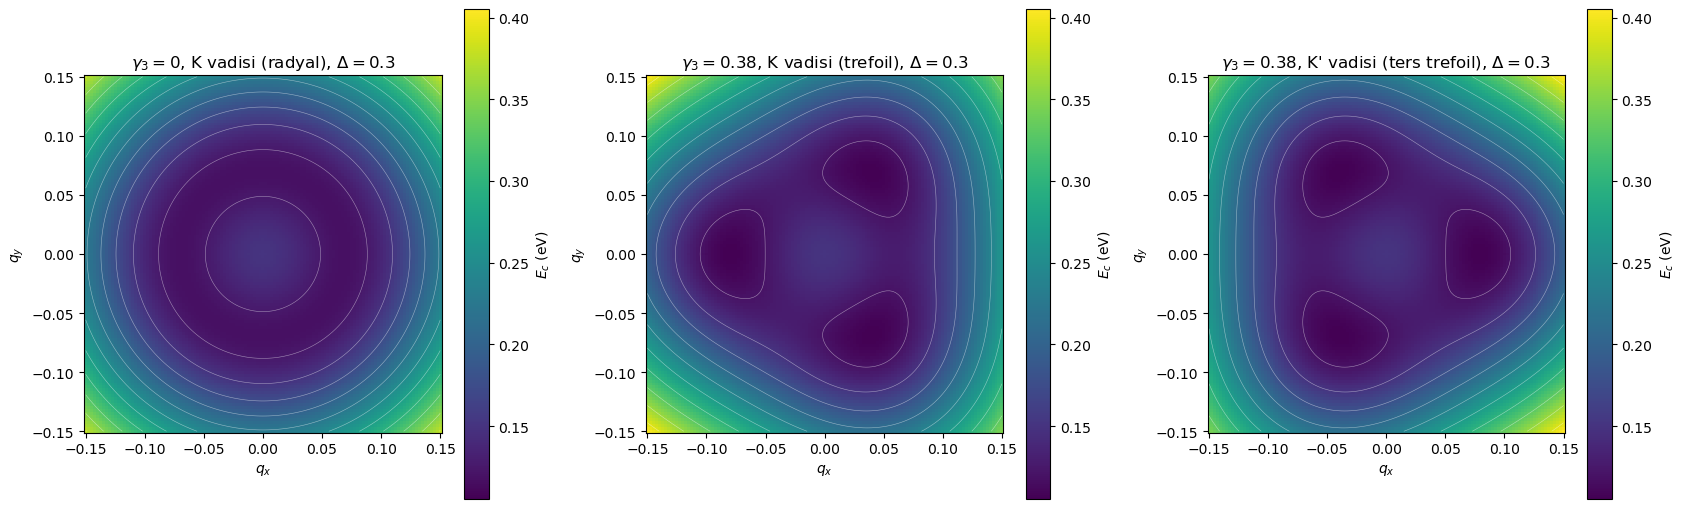

In [5]:
# =====================================================================
#  Cell 4 (DUZELTILMIS) — k·p continuum, dogru anchor'larla
#
#  Onceki kosuda ANCHOR 3'u q=0'da test etmistim — yanlis nokta.
#  Analitik gap formulu  Δγ1/√(γ1²+Δ²)  GLOBAL MINIMUM gap'idir,
#  yani Mexican-hat halkasinin DIBI'nde, q=0'da DEGIL.
#
#  Bu surumde:
#   (1) v3 global degisken kullanmiyoruz, parametre olarak gecirilir
#   (2) ANCHOR 3: global min gap'i ince taramayla bul, formulle kiyasla
#   (3) ANCHOR 5: gercek K-K' karsilastirmasi — global min enerjileri
#       iki vadi icin esit olmali (zaman-tersi)
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt

# Parametreler (McCann-Koshino 2013)
g0 = 3.16
g1 = 0.38
g3 = 0.38
a  = 1.0
v  = (np.sqrt(3)/2) * a * g0
v3_default = (np.sqrt(3)/2) * a * g3

def H_kp(qx, qy, delta, xi=+1, v3=v3_default):
    """4×4 BLG k·p, baz (A1,B1,A2,B2). xi=+1 (K) veya -1 (K')."""
    pi  = xi*qx + 1j*qy
    pid = xi*qx - 1j*qy
    return np.array([
        [+delta/2,    v*pid,       0.0,          -v3*pi   ],
        [v*pi,        +delta/2,    g1,           0.0      ],
        [0.0,         g1,          -delta/2,     v*pid    ],
        [-v3*pid,     0.0,         v*pi,         -delta/2 ],
    ], dtype=complex)


# ---- ANCHOR 1: Hermitiklik ----
H_test = H_kp(0.05, 0.03, 0.3)
herm = np.max(np.abs(H_test - H_test.conj().T))
print(f"[ANCHOR 1] Hermitiklik = {herm:.2e}")

# ---- ANCHOR 2: q=0, Δ=0 -> {-γ1, 0, 0, +γ1} ----
e0 = np.linalg.eigvalsh(H_kp(0, 0, 0.0))
print(f"\n[ANCHOR 2] q=0, Δ=0: {np.round(e0, 6)}")
print(f"           beklenen: {[-g1, 0, 0, g1]}")
err2 = np.max(np.abs(np.sort(e0) - np.sort([-g1, 0, 0, g1])))
print(f"           fark = {err2:.2e}")

# ---- ANCHOR 3: GLOBAL MIN gap'i analitik ile karsilastir ----
def min_gap(delta, xi=+1, v3=v3_default, dq=0.12, n=201):
    """Alt iletim - üst valans gap'inin q-uzayinda global min'i."""
    qxv = np.linspace(-dq, dq, n)
    qyv = np.linspace(-dq, dq, n)
    QX, QY = np.meshgrid(qxv, qyv)
    gmin = np.inf
    q_at = (0.0, 0.0)
    for i in range(n):
        for j in range(n):
            e = np.linalg.eigvalsh(H_kp(QX[i,j], QY[i,j], delta, xi, v3))
            g = e[2] - e[1]
            if g < gmin:
                gmin = g; q_at = (QX[i,j], QY[i,j])
    return gmin, q_at

print(f"\n[ANCHOR 3] Global min gap (γ3 KAPALI'da analitik tutmali):")
print(f"{'Δ':>6} {'min_gap':>11} {'analitik':>11} {'fark':>10} {'q* yeri':>20}")
for dlt in [0.1, 0.3, 0.5, 0.8]:
    gmin, q_at = min_gap(dlt, v3=0.0)
    ana = abs(dlt) * g1 / np.sqrt(g1**2 + dlt**2)
    print(f"{dlt:>6.2f} {gmin:>11.6f} {ana:>11.6f} {abs(gmin-ana):>10.2e}  "
          f"({q_at[0]:+.4f}, {q_at[1]:+.4f})")

# γ3 acikken trefoil pocket'a kayar; analitik formul tam tutmaz ama
# γ3 -> 0 limitinde tutmali. Bunu da kontrol.
print(f"\n[ANCHOR 3b] γ3 acik (gercek BLG):")
print(f"{'Δ':>6} {'min_gap':>11} {'γ3=0 analitik':>15} {'gap_K=Δγ1/...':>14}")
for dlt in [0.1, 0.3, 0.5, 0.8]:
    gmin, q_at = min_gap(dlt, v3=v3_default)
    ana = abs(dlt) * g1 / np.sqrt(g1**2 + dlt**2)
    print(f"{dlt:>6.2f} {gmin:>11.6f} {ana:>15.6f}   "
          f"(γ3 ile min biraz dusuk olmali)")

# ---- ANCHOR 4: C3 simetrisi (γ3 ile) ----
def R120(qx, qy):
    c, s = np.cos(2*np.pi/3), np.sin(2*np.pi/3)
    return c*qx - s*qy, s*qx + c*qy

qtx, qty = 0.06, 0.0
qr1x, qr1y = R120(qtx, qty)
qr2x, qr2y = R120(qr1x, qr1y)
e_o  = np.linalg.eigvalsh(H_kp(qtx, qty, 0.3))
e_r1 = np.linalg.eigvalsh(H_kp(qr1x, qr1y, 0.3))
e_r2 = np.linalg.eigvalsh(H_kp(qr2x, qr2y, 0.3))
c3_err = max(np.max(np.abs(e_o - e_r1)), np.max(np.abs(e_r1 - e_r2)))
print(f"\n[ANCHOR 4] C3 simetrisi (alt iletim band E_c, üç q noktasinda):")
print(f"           E_c orig = {e_o[2]:.6f}, R120 = {e_r1[2]:.6f}, "
      f"R240 = {e_r2[2]:.6f}")
print(f"           tum bant farki = {c3_err:.2e}  (~1e-15)")

# ---- ANCHOR 5: GERCEK K vs K' Kramers ----
# Zaman-tersi: spinsiz BLG'de T = K·C (kompleks eslenik).
# Beklenti: E_K(q) == E_K'(-q), her bant icin.
# Yani aynı q'da K ve K' bantlari farkli olabilir, ama
# (q, K) ile (-q, K') ozdes spektrum vermeli.
q1 = (0.04, 0.02)
e_Kq    = np.linalg.eigvalsh(H_kp(+q1[0], +q1[1], 0.3, xi=+1))
e_Kpmq  = np.linalg.eigvalsh(H_kp(-q1[0], -q1[1], 0.3, xi=-1))
kram_err = np.max(np.abs(e_Kq - e_Kpmq))
print(f"\n[ANCHOR 5] Kramers: E_K(q)  vs  E_K'(-q)  ayni mi?")
print(f"           E_K (+q)  = {np.round(e_Kq, 6)}")
print(f"           E_K'(-q)  = {np.round(e_Kpmq, 6)}")
print(f"           fark = {kram_err:.2e}  (~1e-15)")

# Karsi-test: ayni q'da K ve K' FARKLI olmali (γ3 sebebiyle trefoil
# yonu valley'e bagimli)
e_Kq2  = np.linalg.eigvalsh(H_kp(0.06, 0.0, 0.3, xi=+1))
e_Kpq2 = np.linalg.eigvalsh(H_kp(0.06, 0.0, 0.3, xi=-1))
print(f"\n           [karsi-test] aynı q=(0.06,0) ama farkli vadi:")
print(f"             E_K  = {np.round(e_Kq2, 6)}")
print(f"             E_K' = {np.round(e_Kpq2, 6)}")
print(f"             fark = {np.max(np.abs(e_Kq2 - e_Kpq2)):.2e}  "
      f"(0 OLMAMALI — trefoil valley-baginimi)")

# ---- Cizimler ----
def Ec_map(delta, v3_val, dq=0.15, n=121):
    qxv = np.linspace(-dq, dq, n)
    qyv = np.linspace(-dq, dq, n)
    QX, QY = np.meshgrid(qxv, qyv)
    E = np.zeros(QX.shape)
    for i in range(n):
        for j in range(n):
            E[i,j] = np.linalg.eigvalsh(H_kp(QX[i,j], QY[i,j], delta,
                                              +1, v3_val))[2]
    return QX, QY, E

QX, QY, E_off = Ec_map(0.3, 0.0)
_,  _,  E_on  = Ec_map(0.3, v3_default)
_,  _,  E_Kp  = Ec_map(0.3, v3_default)   # K' icin: ayni dq aralginda
# K' icin yeniden hesapla, xi=-1
qxv = np.linspace(-0.15, 0.15, 121)
qyv = np.linspace(-0.15, 0.15, 121)
E_Kp2 = np.zeros((121,121))
for i in range(121):
    for j in range(121):
        E_Kp2[i,j] = np.linalg.eigvalsh(
            H_kp(qxv[j], qyv[i], 0.3, -1, v3_default))[2]

fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
vmax = max(E_off.max(), E_on.max(), E_Kp2.max())
vmin = min(E_off.min(), E_on.min(), E_Kp2.min())
for a_ax, E, ttl in [
    (ax[0], E_off, r'$\gamma_3=0$, K vadisi (radyal)'),
    (ax[1], E_on,  r'$\gamma_3=0.38$, K vadisi (trefoil)'),
    (ax[2], E_Kp2, r"$\gamma_3=0.38$, K' vadisi (ters trefoil)"),
]:
    im = a_ax.pcolormesh(QX, QY, E, cmap='viridis', shading='auto',
                          vmin=vmin, vmax=vmax)
    a_ax.contour(QX, QY, E, levels=10, colors='white', linewidths=0.4, alpha=0.5)
    a_ax.set_xlabel(r'$q_x$'); a_ax.set_ylabel(r'$q_y$')
    a_ax.set_title(ttl + r', $\Delta=0.3$')
    a_ax.set_aspect('equal')
    plt.colorbar(im, ax=a_ax, label='$E_c$ (eV)')
plt.tight_layout()
plt.show()

In [6]:
# =====================================================================
#  Cell 5c — Eigsh yontemleri: AYNI H'de uc yontem, OUTPUT KISITLI
#
#  Cell 5b'de output kesildi (VSCode kısaltma). Bu sefer minimal
#  yazi, sadece "calisti mi" + "ilk 4 ozdeger" tarzi kompakt cikti.
# =====================================================================
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import time

# H yeniden insa (Cell 5a/5b ile aynisi)
a_nm = 0.246
g0, g1 = 3.16, 0.38
g3 = 0.38
v  = (np.sqrt(3)/2) * a_nm * g0
v3 = (np.sqrt(3)/2) * a_nm * g3
N, L_box = 21, 60.0
h = L_box / (N - 1); Nsq = N*N

def D1(N, h):
    return sp.diags([np.ones(N-1)/(2*h), -np.ones(N-1)/(2*h)],
                    [+1, -1], shape=(N, N), format='csr')

I_N = sp.eye(N, format='csr')
Dx = sp.kron(I_N, D1(N, h), format='csr')
Dy = sp.kron(D1(N, h), I_N, format='csr')
QX, QY = -1j*Dx, -1j*Dy
PI, PID = QX + 1j*QY, QX - 1j*QY

delta = 0.3
I_full = sp.eye(Nsq, format='csr')
Z = sp.csr_matrix((Nsq, Nsq), dtype=complex)
H = sp.bmat([
    [(+delta/2)*I_full,  v*PID,   Z,                  -v3*PI ],
    [v*PI,    (+delta/2)*I_full,  g1*I_full,          Z      ],
    [Z,                  g1*I_full,  (-delta/2)*I_full,  v*PID ],
    [-v3*PID,            Z,       v*PI,               (-delta/2)*I_full],
], format='csr')

# Dense ref: ilk 4 |E|
e_d = np.linalg.eigvalsh(H.toarray())
e_d_near = np.sort(e_d[np.argsort(np.abs(e_d))[:4]])
print(f"DENSE ilk 4 |E|: {e_d_near}")

# Yol 1
print("\nYOL 1 — eigsh sigma=0:")
try:
    t = time.time()
    e1, _ = spla.eigsh(H, k=4, sigma=0.0, which='LM')
    print(f"  OK ({time.time()-t:.2f} s)")
    print(f"  ilk 4: {np.sort(e1)}")
    print(f"  dense ile max fark: "
          f"{np.max(np.abs(np.sort(e1) - e_d_near)):.2e}")
except Exception as e:
    print(f"  FAIL: {type(e).__name__}: {e}")

# Yol 2
print("\nYOL 2 — eigsh which='SM':")
try:
    t = time.time()
    e2, _ = spla.eigsh(H, k=4, which='SM')
    print(f"  OK ({time.time()-t:.2f} s)")
    print(f"  ilk 4: {np.sort(e2)}")
except Exception as e:
    print(f"  FAIL: {type(e).__name__}: {e}")

# Yol 3
print("\nYOL 3 — eigsh(H^2, SM):")
try:
    t = time.time()
    H2 = H @ H
    e3sq, _ = spla.eigsh(H2, k=4, which='SM')
    print(f"  OK ({time.time()-t:.2f} s)")
    print(f"  |E| = sqrt({np.sort(e3sq)}) = "
          f"{np.sqrt(np.sort(np.abs(e3sq)))}")
except Exception as e:
    print(f"  FAIL: {type(e).__name__}: {e}")

DENSE ilk 4 |E|: [-0.10543535 -0.10539572  0.10539572  0.10543535]

YOL 1 — eigsh sigma=0:
  OK (0.51 s)
  ilk 4: [-0.10543535 -0.10539572  0.10539572  0.10543535]
  dense ile max fark: 1.26e-15

YOL 2 — eigsh which='SM':
  OK (1.41 s)
  ilk 4: [-0.10543535 -0.10539572  0.10539572  0.10543535]

YOL 3 — eigsh(H^2, SM):
  OK (0.95 s)
  |E| = sqrt([0.01110826 0.01110826 0.01111661 0.01111661]) = [0.10539572 0.10539572 0.10543535 0.10543535]


Grid: 41x41, h=2.000 nm, dim=6724
Dense matris bellek: 0.72 GB (kompleks128)

[1] H insa...
    OK (0.01 s)  nnz=49444
    Hermitik: 0.00e+00

[2] Bant referansi (U0=0):
    Dense eigh: 55.40 s
    E=0 etrafindaki 8 ozdeger (meV):
      -45.865
      -45.762
      -45.762
      -45.535
      +45.535
      +45.762
      +45.762
      +45.865
    Sayisal bant min ~ +45.53 meV

[3] QD spektrumu:
    Dense eigh: 48.33 s
    E=0 etrafindaki 10 ozdeger (meV):
      E_0 = +8.691
      E_1 = +8.693
      E_2 = +8.693
      E_3 = +8.696
      E_4 = +16.443
      E_5 = +16.445
      E_6 = +16.456
      E_7 = +16.458
      E_8 = +18.013
      E_9 = +18.015

    Iletim tarafinda baglı durum: 10
    Valans tarafinda baglı durum: 0
    Δ_01 (iletim) = 0.002 meV


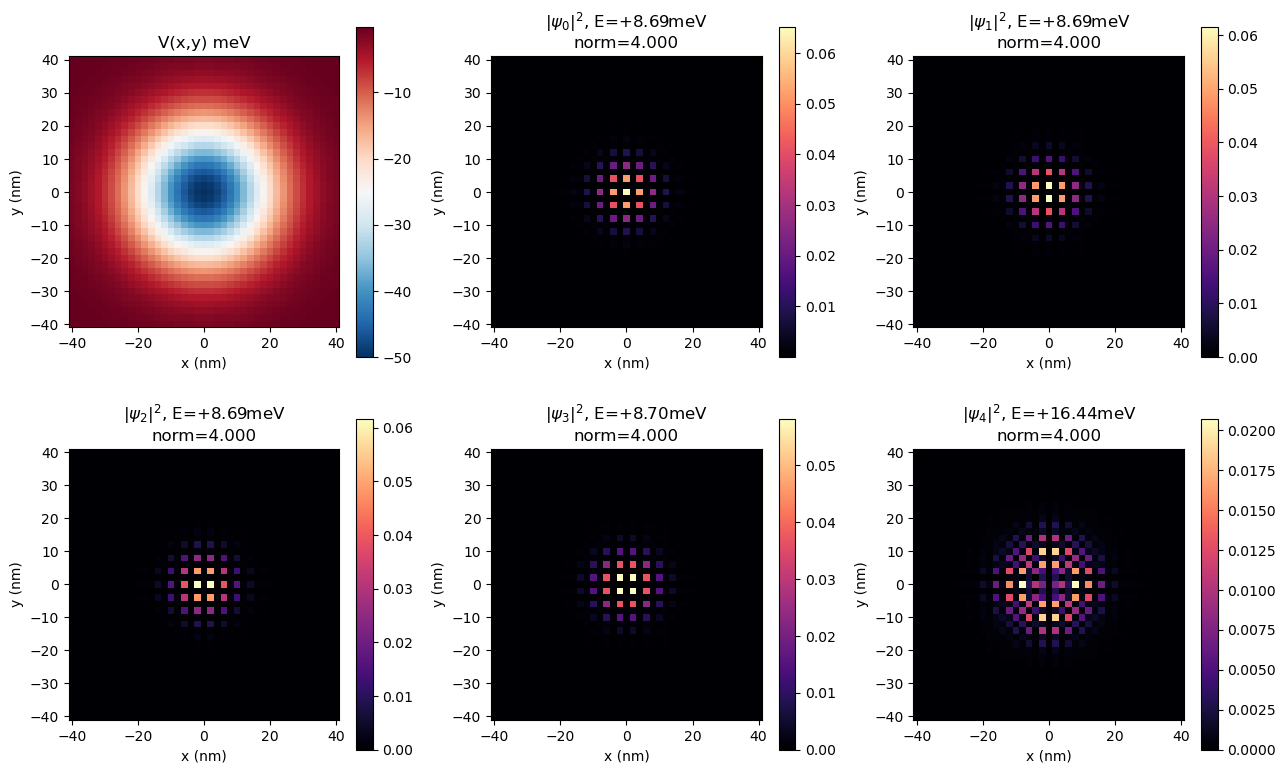


>>> Kaydedildi: <TMPDIR>/qd_states.png


In [7]:
# =====================================================================
#  Cell 5f — DENSE eigh (shift-invert YOK, MKL/SuperLU YOK)
#
#  Conda quantum_lab Windows ortaminda spla.eigsh(sigma=+) kernel'i
#  oldurdu. Dense eigh'a geciyoruz: 4·41² = 6724 boyut, 720 MB,
#  16 GB RAM'de rahat. scipy.linalg.eigh subset_by_index ile sadece
#  istedigimiz ozdegerleri verir.
#
#  CALISTIRMADAN ONCE: Kernel -> Restart
# =====================================================================
import numpy as np
import scipy.sparse as sp
import scipy.linalg as sla         # DENSE eigh icin
import matplotlib.pyplot as plt
import time, os, tempfile, gc

TMP = tempfile.gettempdir()

# Parametreler
a_nm = 0.246
g0, g1, g3 = 3.16, 0.38, 0.38
v  = (np.sqrt(3)/2) * a_nm * g0
v3 = (np.sqrt(3)/2) * a_nm * g3

L_box = 80.0
N     = 41
h     = L_box / (N - 1)
Nsq   = N*N
dim   = 4*Nsq
print(f"Grid: {N}x{N}, h={h:.3f} nm, dim={dim}")
print(f"Dense matris bellek: {dim*dim*16/1e9:.2f} GB (kompleks128)")

xs = np.linspace(-L_box/2, L_box/2, N)
ys = np.linspace(-L_box/2, L_box/2, N)

D1 = sp.diags([np.ones(N-1)/(2*h), -np.ones(N-1)/(2*h)],
              [+1, -1], shape=(N, N), format='csr')
I_N = sp.eye(N, format='csr')
Dx = sp.kron(I_N, D1, format='csr')
Dy = sp.kron(D1, I_N, format='csr')
QX, QY = -1j*Dx, -1j*Dy

def build_H_dot(delta_ext, U0, L_dot, xi=+1):
    XX, YY = np.meshgrid(xs, ys, indexing='xy')
    V2d = -U0 * np.exp(-(XX**2 + YY**2) / (2 * L_dot**2))
    Vmat = sp.diags(V2d.flatten(), 0, format='csr')
    PI  = xi*QX + 1j*QY
    PID = xi*QX - 1j*QY
    I_full = sp.eye(Nsq, format='csr')
    Z = sp.csr_matrix((Nsq, Nsq), dtype=complex)
    Hdp = (+delta_ext/2) * I_full + Vmat
    Hdm = (-delta_ext/2) * I_full + Vmat
    G1  = g1 * I_full
    H = sp.bmat([
        [Hdp,        v*PID,    Z,          -v3*PI],
        [v*PI,       Hdp,      G1,         Z     ],
        [Z,          G1,       Hdm,        v*PID ],
        [-v3*PID,    Z,        v*PI,       Hdm   ],
    ], format='csr')
    return H, V2d

def get_low_energy_states(H_sparse, n_below=4, n_above=4):
    """H'yi yogunlastir, eigvalsh yap, E=0'a en yakin 2n ozdeger ve
    ozdurum don. RAM: dim²·16 byte."""
    H_dense = H_sparse.toarray()
    # Hermitik garantisi (sayisal asimetri için)
    H_dense = 0.5 * (H_dense + H_dense.conj().T)
    # Tam spektrum hesapla (zaten dim cikiyor)
    evals, evecs = sla.eigh(H_dense)
    del H_dense; gc.collect()
    # E=0'a yakin 2n tane sec
    idx_sort = np.argsort(np.abs(evals))
    idx_keep = np.sort(idx_sort[:n_below + n_above])
    return evals[idx_keep], evecs[:, idx_keep]

# [1] H insa
print("\n[1] H insa...")
t = time.time()
H_qd, V2d = build_H_dot(delta_ext=0.10, U0=0.05, L_dot=15.0)
print(f"    OK ({time.time()-t:.2f} s)  nnz={H_qd.nnz}")

diff = H_qd - H_qd.conj().T
herm = float(np.max(np.abs(diff.data))) if diff.nnz > 0 else 0.0
print(f"    Hermitik: {herm:.2e}")
del diff

# [2] Bant referansi (DENSE)
print("\n[2] Bant referansi (U0=0):")
H0, _ = build_H_dot(delta_ext=0.10, U0=0.0, L_dot=15.0)
t = time.time()
e0_low, _ = get_low_energy_states(H0, 4, 4)
print(f"    Dense eigh: {time.time()-t:.2f} s")
print(f"    E=0 etrafindaki 8 ozdeger (meV):")
for e in e0_low:
    print(f"      {e*1000:+.3f}")
band_min_pos = np.min(e0_low[e0_low > 0])
print(f"    Sayisal bant min ~ +{band_min_pos*1000:.2f} meV")
del H0; gc.collect()

# [3] QD spektrumu (DENSE)
print(f"\n[3] QD spektrumu:")
t = time.time()
e_qd, vecs_qd = get_low_energy_states(H_qd, 6, 4)
print(f"    Dense eigh: {time.time()-t:.2f} s")
print(f"    E=0 etrafindaki 10 ozdeger (meV):")
for i, e in enumerate(e_qd):
    print(f"      E_{i} = {e*1000:+.3f}")
bound_pos = e_qd[(e_qd > 0) & (e_qd < band_min_pos)]
bound_neg = e_qd[(e_qd < 0) & (e_qd > -band_min_pos)]
print(f"\n    Iletim tarafinda baglı durum: {len(bound_pos)}")
print(f"    Valans tarafinda baglı durum: {len(bound_neg)}")
if len(bound_pos) >= 2:
    print(f"    Δ_01 (iletim) = "
          f"{(bound_pos[1]-bound_pos[0])*1000:.3f} meV")

# [4] Cizimler
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
im = axes[0,0].pcolormesh(xs, ys, V2d*1000, cmap='RdBu_r', shading='auto')
axes[0,0].set_title('V(x,y) meV')
axes[0,0].set_xlabel('x (nm)'); axes[0,0].set_ylabel('y (nm)')
axes[0,0].set_aspect('equal'); plt.colorbar(im, ax=axes[0,0])

# Iletim bantindan 5 durum (pozitif tarafa en yakinlar)
pos_idx = np.where(e_qd > 0)[0][:5]
for plot_k, k in enumerate(pos_idx):
    psi = vecs_qd[:, k].reshape(4, N, N)
    prob = np.sum(np.abs(psi)**2, axis=0)
    norm = prob.sum() * h * h
    ax = axes[(plot_k+1)//3, (plot_k+1)%3]
    im = ax.pcolormesh(xs, ys, prob, cmap='magma', shading='auto')
    ax.set_title(f'$|\\psi_{plot_k}|^2$, E={e_qd[k]*1000:+.2f}meV\n'
                 f'norm={norm:.3f}')
    ax.set_xlabel('x (nm)'); ax.set_ylabel('y (nm)')
    ax.set_aspect('equal'); plt.colorbar(im, ax=ax)

plt.tight_layout()
img_path = os.path.join(TMP, 'qd_states.png')
plt.savefig(img_path, dpi=100, bbox_inches='tight')
plt.show()
print(f"\n>>> Kaydedildi: {img_path}")

v = 0.6732, v3 = 0.0810 eV·nm

Baz: L_box=120.0 nm, dq=0.0524 nm^-1, q_max=0.5 nm^-1
     Toplam plane wave: 293,  Hilbert dim = 1172
H_kin yapildi: 0.00 s,  bellek 22.0 MB
V_mat yapildi: 0.01 s

[ANCHOR 0] Hermitiklik = 0.00e+00

[ANCHOR 1] V=0 limiti  (eigh: 0.08 s):
   En kucuk |E| 8 (eV):
     -0.04689
     -0.04640
     -0.04640
     -0.04553
     +0.04553
     +0.04640
     +0.04640
     +0.04689
   Beklenti: bant min ~ ±48.35 meV (γ3=0 analitik, γ3 ile ~%10 dusuk)

[ANCHOR 2] Tam spektrum (eigh: 0.38 s):
   E=0 etrafinda 12 ozdeger (meV):
       +8.979  <-- bant min altinda?
      +17.053  <-- bant min altinda?
      +18.667  <-- bant min altinda?
      +27.165  <-- bant min altinda?
      +27.355  <-- bant min altinda?
      +30.197  <-- bant min altinda?
      +35.241  <-- bant min altinda?
      +35.759  <-- bant min altinda?
      +36.700  <-- bant min altinda?
      +39.370  <-- bant min altinda?
      +41.546  <-- bant min altinda?
      +42.024  <-- bant min altinda?

   

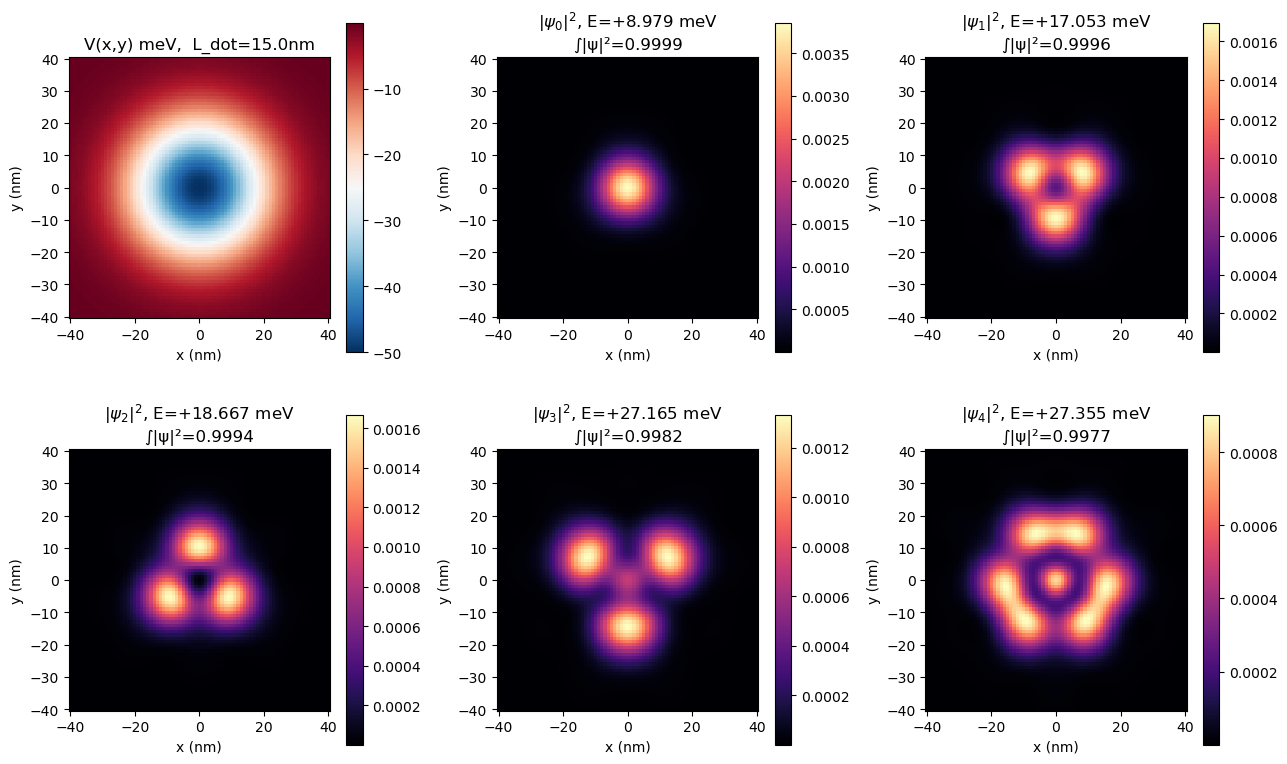

In [8]:
# =====================================================================
#  Cell 5g — DUZLEM-DALGA BAZI (Knothe-Falko 2018, Mayer-Knothe 2023)
#
#  Sonlu fark YOK -> fermion doubling YOK.
#  Baz: {e^{iq·r}/L_box : |q| < q_max}, q'lar 2pi/L_box arali grid.
#
#  H = H_kin + V_mat
#    H_kin: blok-kosegen 4x4 H_kp(q_n) her q_n'de
#    V_mat: vadi-disi, V_nm = V_FT(q_n - q_m) / L_box^2,
#           V(r) = -U0 exp(-r^2/(2 L_dot^2))
#           V_FT(q) = -U0 * 2pi * L_dot^2 * exp(-q^2 * L_dot^2 / 2)
#    Potansiyel 4 bandi esit kaydirir (skaler kapi) -> Vmat ⊗ I_4
#
#  Anchorlar:
#   (1) V=0 -> ozdegerler tam k·p bantlari (her q_n'de 4 deger)
#   (2) Cok kucuk U0 ile QD baglanma yok, sadece kucuk perturbasyon
#   (3) Buyuk L_box / kucuk q_max -> baz tutarli, sonuc yakinsamali
# =====================================================================
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt
import time

# ---- Fiziksel parametreler (Knothe-Falko convention, McCann-Koshino) ----
a_nm = 0.246
g0   = 3.16
g1   = 0.38
g3   = 0.38
v    = (np.sqrt(3)/2) * a_nm * g0       # eV·nm
v3   = (np.sqrt(3)/2) * a_nm * g3       # eV·nm
print(f"v = {v:.4f}, v3 = {v3:.4f} eV·nm")

# ---- QD parametreleri ----
delta = 0.100      # 100 meV gap (Knothe-Falko 2018 default)
U0    = 0.050      # 50 meV well depth
L_dot = 15.0       # nm

# ---- Duzlem-dalga bazi ----
L_box = 120.0      # nm — kutu (period)
dq    = 2*np.pi / L_box     # ~0.0524 nm^-1
q_max = 0.50       # nm^-1, kesim
xi    = +1         # K vadisi

# q-grid (Cartesian, sonra |q|<q_max ile filtrele)
n_axis = int(np.ceil(q_max / dq)) + 2
qxs = np.arange(-n_axis, n_axis+1) * dq
qys = np.arange(-n_axis, n_axis+1) * dq
q_pts = [(qx, qy) for qx in qxs for qy in qys
         if qx**2 + qy**2 <= q_max**2]
N_pw = len(q_pts)
print(f"\nBaz: L_box={L_box} nm, dq={dq:.4f} nm^-1, q_max={q_max} nm^-1")
print(f"     Toplam plane wave: {N_pw},  Hilbert dim = {4*N_pw}")

q_arr = np.array(q_pts)     # (N_pw, 2)

# ---- Kinetik: blok-kosegen 4x4 H_kp(q) per plane wave ----
def H_kp(qx, qy, delta, xi=+1, v_val=v, v3_val=v3):
    pi  = xi*qx + 1j*qy
    pid = xi*qx - 1j*qy
    return np.array([
        [+delta/2,    v_val*pid,   0.0,         -v3_val*pi   ],
        [v_val*pi,    +delta/2,    g1,          0.0          ],
        [0.0,         g1,          -delta/2,    v_val*pid    ],
        [-v3_val*pid, 0.0,         v_val*pi,    -delta/2     ],
    ], dtype=complex)

t0 = time.time()
H_kin = np.zeros((4*N_pw, 4*N_pw), dtype=complex)
for n in range(N_pw):
    H_kin[4*n:4*n+4, 4*n:4*n+4] = H_kp(q_arr[n,0], q_arr[n,1], delta, xi)
print(f"H_kin yapildi: {time.time()-t0:.2f} s,  bellek "
      f"{H_kin.nbytes/1e6:.1f} MB")

# ---- Potansiyel: V_nm = V_FT(q_n - q_m) / L_box^2 ----
# V(r) = -U0 exp(-r^2 / (2 L_dot^2))
# V_FT(q) = -U0 * 2pi * L_dot^2 * exp(-q^2 * L_dot^2 / 2)
def V_FT(qx, qy):
    return -U0 * 2*np.pi * L_dot**2 * np.exp(
        -(qx**2 + qy**2) * L_dot**2 / 2)

t0 = time.time()
# Vektorlu: V_mat (N_pw, N_pw)
dQx = q_arr[:, 0:1] - q_arr[:, 0:1].T
dQy = q_arr[:, 1:2] - q_arr[:, 1:2].T
V_scalar = V_FT(dQx, dQy) / L_box**2     # (N_pw, N_pw)
# 4-spinor: V her band'a esit eklenir -> Kronecker I_4
V_mat = np.kron(V_scalar, np.eye(4, dtype=complex))
print(f"V_mat yapildi: {time.time()-t0:.2f} s")

# ---- Tam H ----
H_tot = H_kin + V_mat
# Hermitik mi?
herm = np.max(np.abs(H_tot - H_tot.conj().T))
print(f"\n[ANCHOR 0] Hermitiklik = {herm:.2e}")

# ---- ANCHOR 1: V=0 limiti -> kinetik bantlar ----
t0 = time.time()
e_kin = sla.eigvalsh(H_kin)
print(f"\n[ANCHOR 1] V=0 limiti  (eigh: {time.time()-t0:.2f} s):")
print(f"   En kucuk |E| 8 (eV):")
e_kin_near = np.sort(e_kin[np.argsort(np.abs(e_kin))[:8]])
for e in e_kin_near:
    print(f"     {e:+.5f}")
# Beklenti: kinetik = H_kp her q'da blok-kosegen ozdegerleri
# Yani spektrum = {eigenvalues of H_kp(q_n) for all q_n}
# Global min: gap_min ~ Δγ1/sqrt(γ1²+Δ²)/2 = 0.05·0.38/sqrt(0.1538+0.01)/2
gap_min_ana = delta*g1/np.sqrt(g1**2+delta**2)/2
print(f"   Beklenti: bant min ~ ±{gap_min_ana*1000:.2f} meV "
      f"(γ3=0 analitik, γ3 ile ~%10 dusuk)")

# ---- ANCHOR 2: Tam spektrum, baglı durumlar var mi ----
t0 = time.time()
e_full, vecs_full = sla.eigh(H_tot)
print(f"\n[ANCHOR 2] Tam spektrum (eigh: {time.time()-t0:.2f} s):")
# E=0 etrafindaki 12 ozdeger
idx = np.argsort(np.abs(e_full))[:12]
near0 = np.sort(e_full[idx])
print(f"   E=0 etrafinda 12 ozdeger (meV):")
for e in near0:
    flag = "  <-- bant min altinda?" if 0 < e < gap_min_ana else ""
    print(f"     {e*1000:+8.3f}{flag}")

# Iletim tarafi baglı durumlar
bound_pos = e_full[(e_full > 0) & (e_full < gap_min_ana*0.95)]
print(f"\n   Iletim tarafinda baglı: {len(bound_pos)} durum")
if len(bound_pos) >= 2:
    print(f"   Δ_01 = {(bound_pos[1]-bound_pos[0])*1000:.4f} meV")
if len(bound_pos) >= 4:
    print(f"   E_2 - E_0 = {(bound_pos[2]-bound_pos[0])*1000:.4f} meV")
    print(f"   E_3 - E_0 = {(bound_pos[3]-bound_pos[0])*1000:.4f} meV")

# ---- Real-space dalga fonksiyonu (gercek BLG QD haritasi) ----
# ψ(r) = Σ_n c_n^{band} e^{iq_n·r} / L_box, band = 0..3
# |ψ(r)|² = Σ_band |ψ_band(r)|²
def reconstruct_density(c_vec, q_arr, xs_real, ys_real, L_box):
    """c_vec: (4·N_pw,) plane-wave katsayilari, baz: (band, q) sirayla
    Reshape: c_vec.reshape(N_pw, 4) -> c[n, band]
    """
    N_pw = len(q_arr)
    c = c_vec.reshape(N_pw, 4)
    XX, YY = np.meshgrid(xs_real, ys_real, indexing='xy')
    prob = np.zeros(XX.shape)
    for band in range(4):
        psi = np.zeros(XX.shape, dtype=complex)
        for n in range(N_pw):
            phase = q_arr[n, 0]*XX + q_arr[n, 1]*YY
            psi += c[n, band] * np.exp(1j*phase) / L_box
        prob += np.abs(psi)**2
    return prob

# Sadece ilk birkac baglı durum
N_real = 81
xs_real = np.linspace(-40, 40, N_real)
ys_real = np.linspace(-40, 40, N_real)

if len(bound_pos) >= 1:
    # Iletim bantindaki ilk birkac ozdurumun indeksi
    pos_idx = np.where(e_full > 0)[0]
    pos_eigs = e_full[pos_idx]
    pos_order = pos_idx[np.argsort(pos_eigs)]
    n_plot = min(5, len(bound_pos))

    fig, axes = plt.subplots(2, 3, figsize=(13, 8))

    # Potansiyel
    XX_p, YY_p = np.meshgrid(xs_real, ys_real, indexing='xy')
    V_real = -U0 * np.exp(-(XX_p**2 + YY_p**2)/(2*L_dot**2))
    im = axes[0,0].pcolormesh(xs_real, ys_real, V_real*1000, cmap='RdBu_r',
                               shading='auto')
    axes[0,0].set_title(f'V(x,y) meV,  L_dot={L_dot}nm')
    axes[0,0].set_xlabel('x (nm)'); axes[0,0].set_ylabel('y (nm)')
    axes[0,0].set_aspect('equal')
    plt.colorbar(im, ax=axes[0,0])

    for k in range(n_plot):
        idx_k = pos_order[k]
        prob = reconstruct_density(vecs_full[:, idx_k], q_arr,
                                    xs_real, ys_real, L_box)
        # Integral = ∫|ψ|² d²r
        dx = xs_real[1]-xs_real[0]
        norm_int = prob.sum() * dx**2
        ax = axes[(k+1)//3, (k+1)%3]
        im = ax.pcolormesh(xs_real, ys_real, prob, cmap='magma',
                           shading='auto')
        ax.set_title(f'$|\\psi_{k}|^2$, E={e_full[idx_k]*1000:+.3f} meV\n'
                     f'∫|ψ|²={norm_int:.4f}')
        ax.set_xlabel('x (nm)'); ax.set_ylabel('y (nm)')
        ax.set_aspect('equal')
        plt.colorbar(im, ax=ax)

    plt.tight_layout()
    plt.savefig('qd_planewave.png', dpi=100, bbox_inches='tight')
    plt.show()

N_pw = 293, dim = 1172

Δ_ext taramasi: 16 nokta, her biri ~0.5 s = toplam ~8 s

  Δ_ext        E0        E1        E2        E3       Δ01   gap_bulk
---------------------------------------------------------------------------
  0.050     0.327     2.783    10.765    11.117     2.456      24.79
  0.067     5.722     7.789    16.163    16.456     2.067      32.83
  0.083     2.433    11.347    13.153    21.654     8.914      40.70
  0.100     8.979    17.053    18.667    27.165     8.074      48.35
  0.117    15.572    22.751    24.210    32.654     7.179      55.76
  0.133    22.129    28.381    29.703    38.092     6.251      62.91
  0.150    28.586    33.896    35.088    43.434     5.310      69.76
  0.167    34.879    39.257    40.319    48.636     4.378      76.32
  0.183    40.948    44.432    45.361    53.757     3.484      82.56
  0.200    46.729    49.391    50.187    58.801     2.662      88.49
  0.217    52.165    54.113    54.778    63.768     1.948      94.11
  0.233    57.2

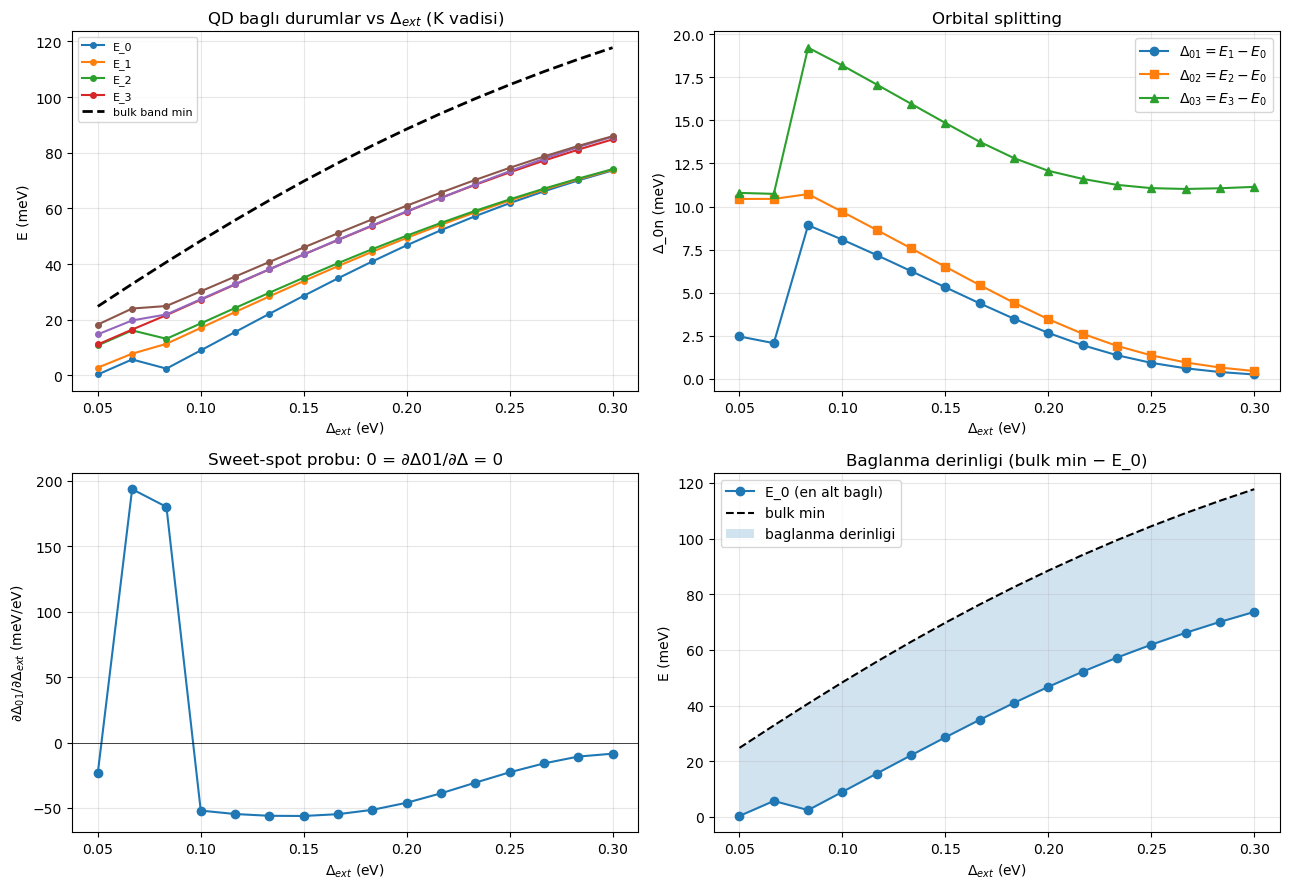

In [9]:
# =====================================================================
#  Cell 6 — Δ_ext TARAMASI: Statik tatli nokta var mi?
#
#  Mayer-Knothe 2023 (pssb 260, 2300395) tarzi: dot parametrelerini
#  sabitle (L_dot=15 nm, U0=50 meV), Δ_ext'i tara, QD spektrumunu
#  diagonalize et, Δ_01 ile orbital splitting'leri kaydet.
#
#  Sorulan: ∂Δ_01/∂Δ_ext = 0 olan bir Δ* var mi?
#    Var ise -> statik tatli nokta -> v3 AC testi anlam kazanir
#    Yok ise -> bu kuyu sekli icin yok -> ya parametre arama,
#               ya da BLG'de de AC dinamik tatli nokta yok demek
#
#  Beklenti (literatur): Δ_01 muhtemelen monoton ama trefoil
#  derinligi ile etkileşimi bilinmiyor — sonuc gercekten ölcecek.
# =====================================================================
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt
import time

# Fiziksel parametreler
a_nm = 0.246
g0, g1, g3 = 3.16, 0.38, 0.38
v    = (np.sqrt(3)/2) * a_nm * g0
v3   = (np.sqrt(3)/2) * a_nm * g3

# QD parametreleri (Cell 5g ile aynı)
U0    = 0.050      # 50 meV
L_dot = 15.0       # nm

# Plane-wave baz (Cell 5g ile aynı)
L_box = 120.0
dq    = 2*np.pi / L_box
q_max = 0.50

n_axis = int(np.ceil(q_max / dq)) + 2
qxs = np.arange(-n_axis, n_axis+1) * dq
qys = np.arange(-n_axis, n_axis+1) * dq
q_pts = [(qx, qy) for qx in qxs for qy in qys
         if qx**2 + qy**2 <= q_max**2]
N_pw = len(q_pts)
q_arr = np.array(q_pts)
print(f"N_pw = {N_pw}, dim = {4*N_pw}")

# Potansiyel matris elemanlari — Δ_ext'e bagımsız, bir kere hesapla
def V_FT(qx, qy):
    return -U0 * 2*np.pi * L_dot**2 * np.exp(
        -(qx**2 + qy**2) * L_dot**2 / 2)

dQx = q_arr[:, 0:1] - q_arr[:, 0:1].T
dQy = q_arr[:, 1:2] - q_arr[:, 1:2].T
V_scalar = V_FT(dQx, dQy) / L_box**2
V_mat = np.kron(V_scalar, np.eye(4, dtype=complex))

# Kinetik H — Δ_ext'e bağlı, her noktada yeniden kur
def H_kp(qx, qy, delta, xi=+1):
    pi  = xi*qx + 1j*qy
    pid = xi*qx - 1j*qy
    return np.array([
        [+delta/2,    v*pid,       0.0,         -v3*pi   ],
        [v*pi,        +delta/2,    g1,          0.0      ],
        [0.0,         g1,          -delta/2,    v*pid    ],
        [-v3*pid,     0.0,         v*pi,        -delta/2 ],
    ], dtype=complex)

def solve_QD(delta_ext, xi=+1, n_low=8):
    H_kin = np.zeros((4*N_pw, 4*N_pw), dtype=complex)
    for n in range(N_pw):
        H_kin[4*n:4*n+4, 4*n:4*n+4] = H_kp(
            q_arr[n,0], q_arr[n,1], delta_ext, xi)
    H_tot = H_kin + V_mat
    e = sla.eigvalsh(H_tot)
    # En kucuk n_low pozitif (iletim taraf bagli durumlari)
    pos = np.sort(e[e > 0])
    return pos[:n_low]

# ---- Tarama ----
deltas = np.linspace(0.05, 0.30, 16)
print(f"\nΔ_ext taramasi: {len(deltas)} nokta, "
      f"her biri ~0.5 s = toplam ~{len(deltas)*0.5:.0f} s\n")

print(f"{'Δ_ext':>7} {'E0':>9} {'E1':>9} {'E2':>9} {'E3':>9} "
      f"{'Δ01':>9} {'gap_bulk':>10}")
print("-" * 75)
rows = []
t_total = time.time()
for d in deltas:
    t = time.time()
    pos = solve_QD(d, xi=+1, n_low=8)
    elapsed = time.time() - t
    # Bulk min gap (referans icin)
    # γ3=0 limiti analitik:
    gap_bulk = d*g1/np.sqrt(g1**2 + d**2)/2
    D01 = pos[1] - pos[0]
    D02 = pos[2] - pos[0]
    D03 = pos[3] - pos[0]
    rows.append({
        'delta': d, 'E0': pos[0], 'E1': pos[1], 'E2': pos[2],
        'E3': pos[3], 'D01': D01, 'D02': D02, 'D03': D03,
        'gap_bulk': gap_bulk, 'pos_8': pos.tolist(),
    })
    print(f"{d:>7.3f} {pos[0]*1000:>9.3f} {pos[1]*1000:>9.3f} "
          f"{pos[2]*1000:>9.3f} {pos[3]*1000:>9.3f} "
          f"{D01*1000:>9.3f} {gap_bulk*1000:>10.2f}")

print(f"\nToplam: {time.time()-t_total:.1f} s")

# ---- Stasyoner nokta analizi ----
arr = np.array([(r['delta'], r['D01'], r['D02'], r['D03'], r['E0'])
                for r in rows])
D_ext = arr[:,0]; D01 = arr[:,1]; D02 = arr[:,2]; D03 = arr[:,3]; E0 = arr[:,4]

# Sayisal turevler
dD01 = np.gradient(D01, D_ext)
dD02 = np.gradient(D02, D_ext)
dE0  = np.gradient(E0,  D_ext)

def find_zero_crossings(y, x):
    zeros = []
    for i in range(len(y)-1):
        if y[i] * y[i+1] < 0:
            xz = x[i] - y[i]*(x[i+1]-x[i])/(y[i+1]-y[i])
            zeros.append(xz)
    return zeros

print(f"\n[STASYONER NOKTA TESTI]")
print(f"  ∂Δ01/∂Δ_ext sifir gecisleri: {find_zero_crossings(dD01, D_ext)}")
print(f"  ∂Δ02/∂Δ_ext sifir gecisleri: {find_zero_crossings(dD02, D_ext)}")
print(f"  ∂E0/∂Δ_ext  sifir gecisleri: {find_zero_crossings(dE0, D_ext)}")

# En kucuk |∂Δ01/∂Δ_ext| (en duz nokta)
imin = np.argmin(np.abs(dD01))
print(f"\n  En kucuk |∂Δ01/∂Δ_ext|: Δ_ext = {D_ext[imin]:.4f}")
print(f"    Δ01 = {D01[imin]*1000:.4f} meV,  "
      f"|∂Δ01/∂Δ_ext| = {abs(dD01[imin])*1000:.4f} meV/eV")

# ---- Cizimler ----
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# (a) Tum bagli durumlar Δ_ext fonksiyonu
all_pos = np.array([r['pos_8'] for r in rows])  # (N_delta, 8)
gap_bulk_arr = D_ext * g1 / np.sqrt(g1**2 + D_ext**2) / 2
for k in range(6):
    ax[0,0].plot(D_ext, all_pos[:,k]*1000, 'o-', ms=4,
                  label=f'E_{k}' if k < 4 else None)
ax[0,0].plot(D_ext, gap_bulk_arr*1000, 'k--', lw=2,
              label='bulk band min')
ax[0,0].set_xlabel(r'$\Delta_{ext}$ (eV)')
ax[0,0].set_ylabel('E (meV)')
ax[0,0].set_title(r'QD baglı durumlar vs $\Delta_{ext}$ (K vadisi)')
ax[0,0].legend(fontsize=8); ax[0,0].grid(alpha=.3)

# (b) Δ_01, Δ_02, Δ_03
ax[0,1].plot(D_ext, D01*1000, 'o-', label=r'$\Delta_{01}=E_1-E_0$')
ax[0,1].plot(D_ext, D02*1000, 's-', label=r'$\Delta_{02}=E_2-E_0$')
ax[0,1].plot(D_ext, D03*1000, '^-', label=r'$\Delta_{03}=E_3-E_0$')
ax[0,1].set_xlabel(r'$\Delta_{ext}$ (eV)')
ax[0,1].set_ylabel('Δ_0n (meV)')
ax[0,1].set_title('Orbital splitting'); ax[0,1].legend(); ax[0,1].grid(alpha=.3)

# (c) Δ_01 turevi
ax[1,0].plot(D_ext, dD01*1000, 'o-')
ax[1,0].axhline(0, c='k', lw=0.5)
ax[1,0].set_xlabel(r'$\Delta_{ext}$ (eV)')
ax[1,0].set_ylabel(r'$\partial\Delta_{01}/\partial\Delta_{ext}$ (meV/eV)')
ax[1,0].set_title('Sweet-spot probu: 0 = ∂Δ01/∂Δ = 0')
ax[1,0].grid(alpha=.3)

# (d) E0 ve bulk band min — kuyunun ne kadar derin "tutuyor"
ax[1,1].plot(D_ext, E0*1000, 'o-', label='E_0 (en alt baglı)')
ax[1,1].plot(D_ext, gap_bulk_arr*1000, 'k--', label='bulk min')
ax[1,1].fill_between(D_ext, E0*1000, gap_bulk_arr*1000,
                      alpha=0.2, label='baglanma derinligi')
ax[1,1].set_xlabel(r'$\Delta_{ext}$ (eV)')
ax[1,1].set_ylabel('E (meV)')
ax[1,1].set_title('Baglanma derinligi (bulk min − E_0)')
ax[1,1].legend(); ax[1,1].grid(alpha=.3)

plt.tight_layout()
plt.savefig('cell6_sweep.png', dpi=100, bbox_inches='tight')
plt.show()

N_pw = 293, dim = 1172, U0 = 20 meV

  Δ_ext   gap_bulk        E0        E1        E2       Δ01  U0/bulk
--------------------------------------------------------------------------------
  0.050      24.79    12.086    17.216    17.706    5.1298    0.807
  0.067      32.83    19.181    23.844    24.299    4.6637    0.609
  0.083      40.70    26.349    30.447    30.865    4.0976    0.491
  0.100      48.35    33.490    36.961    37.337    3.4707    0.414
  0.117      55.76    40.527    43.337    43.668    2.8096    0.359
  0.133      62.91    47.383    49.529    49.811    2.1459    0.318
  0.150      69.76    53.972    55.496    55.726    1.5242    0.287
  0.167      76.32    60.202    61.200    61.380    0.9981    0.262
  0.183      82.56    66.012    66.618    66.752    0.6058    0.242
  0.200      88.49    71.388    71.735    71.831    0.3474    0.226
  0.217      94.11    76.355    76.548    76.614    0.1923    0.213
  0.233      99.42    80.954    81.058    81.103    0.1043    0.20

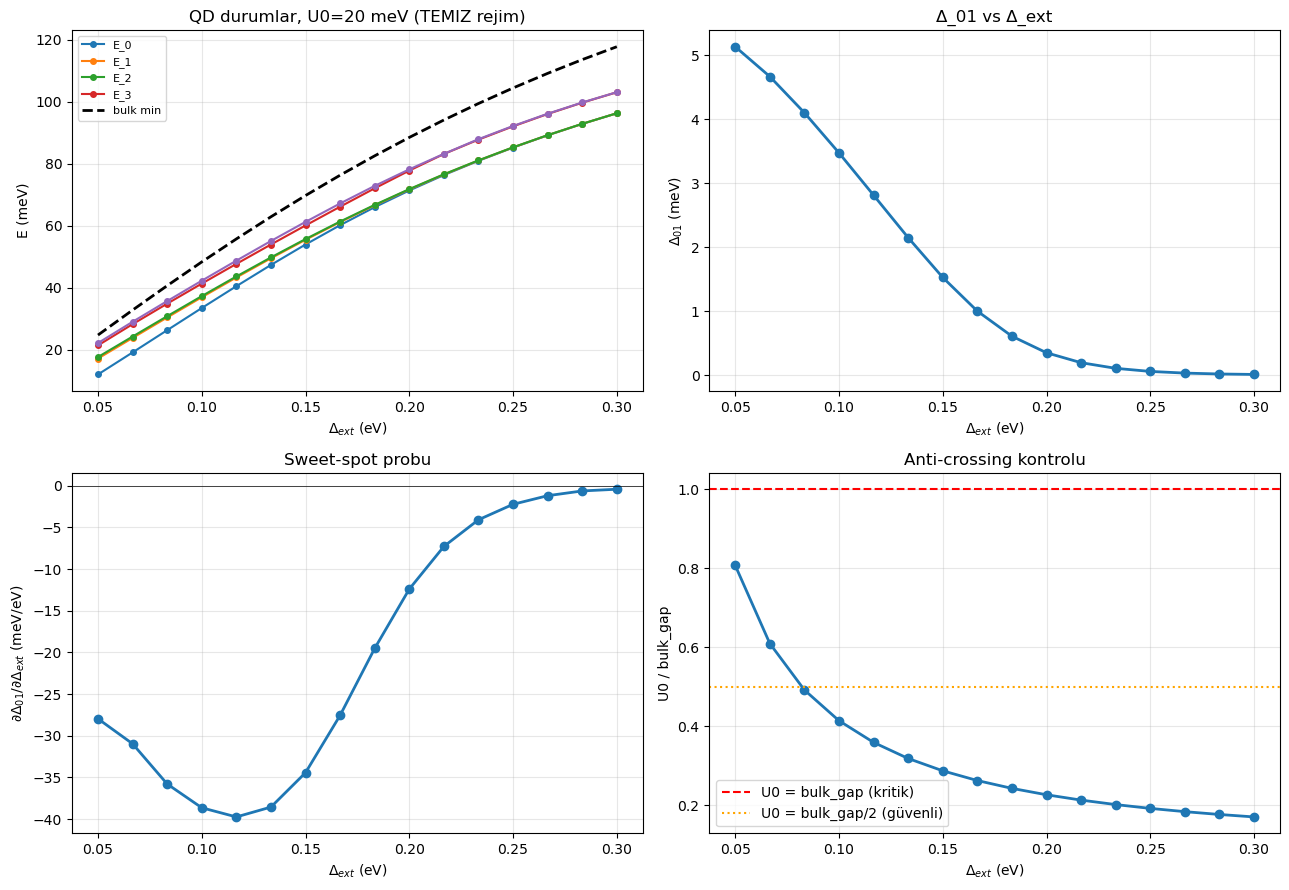

In [10]:
# =====================================================================
#  Cell 6b — TEMIZ BAGLAMA REJIMINDE Δ_ext taramasi
#
#  Cell 6 hukum: Δ_ext < 0.10'da U0=50 meV bulk gap'i asiyor ->
#  anti-crossing artefakti, ozgun sweet-spot DEGIL.
#
#  Bu sefer: U0 = 20 meV (bulk gap'in iyi altinda, Δ_ext > 0.04 icin
#  bulk gap = Δγ1/sqrt(γ1²+Δ²)/2 > 20 meV).
#  Tarama araligi: Δ_ext ∈ [0.05, 0.30], 16 nokta.
#
#  Beklenti: Anti-crossing yok, Δ_01(Δ_ext) duzgun. Mayer-Knothe'nin
#  "perturbative confinement" rejimi.
# =====================================================================
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt
import time

# Fizik
a_nm = 0.246
g0, g1, g3 = 3.16, 0.38, 0.38
v    = (np.sqrt(3)/2) * a_nm * g0
v3   = (np.sqrt(3)/2) * a_nm * g3

# QD: DAHA SIG kuyu
U0    = 0.020      # 20 meV
L_dot = 15.0       # nm

# Plane-wave baz (Cell 5g/6 ile aynı)
L_box = 120.0
dq    = 2*np.pi / L_box
q_max = 0.50

n_axis = int(np.ceil(q_max / dq)) + 2
qxs = np.arange(-n_axis, n_axis+1) * dq
qys = np.arange(-n_axis, n_axis+1) * dq
q_pts = [(qx, qy) for qx in qxs for qy in qys
         if qx**2 + qy**2 <= q_max**2]
N_pw = len(q_pts)
q_arr = np.array(q_pts)
print(f"N_pw = {N_pw}, dim = {4*N_pw}, U0 = {U0*1000:.0f} meV")

# V matrisi
def V_FT(qx, qy):
    return -U0 * 2*np.pi * L_dot**2 * np.exp(
        -(qx**2 + qy**2) * L_dot**2 / 2)

dQx = q_arr[:, 0:1] - q_arr[:, 0:1].T
dQy = q_arr[:, 1:2] - q_arr[:, 1:2].T
V_scalar = V_FT(dQx, dQy) / L_box**2
V_mat = np.kron(V_scalar, np.eye(4, dtype=complex))

def H_kp(qx, qy, delta, xi=+1):
    pi  = xi*qx + 1j*qy
    pid = xi*qx - 1j*qy
    return np.array([
        [+delta/2,    v*pid,       0.0,         -v3*pi   ],
        [v*pi,        +delta/2,    g1,          0.0      ],
        [0.0,         g1,          -delta/2,    v*pid    ],
        [-v3*pid,     0.0,         v*pi,        -delta/2 ],
    ], dtype=complex)

def solve_QD(delta_ext, xi=+1, n_low=8):
    H_kin = np.zeros((4*N_pw, 4*N_pw), dtype=complex)
    for n in range(N_pw):
        H_kin[4*n:4*n+4, 4*n:4*n+4] = H_kp(
            q_arr[n,0], q_arr[n,1], delta_ext, xi)
    H_tot = H_kin + V_mat
    e = sla.eigvalsh(H_tot)
    pos = np.sort(e[e > 0])
    return pos[:n_low]

# ---- Tarama ----
deltas = np.linspace(0.05, 0.30, 16)
print(f"\n{'Δ_ext':>7} {'gap_bulk':>10} {'E0':>9} {'E1':>9} "
      f"{'E2':>9} {'Δ01':>9} {'U0/bulk':>8}")
print("-" * 80)
rows = []
for d in deltas:
    pos = solve_QD(d, xi=+1, n_low=8)
    gap_bulk = d*g1/np.sqrt(g1**2 + d**2)/2
    D01 = pos[1] - pos[0]
    ratio = U0 / gap_bulk
    rows.append({
        'delta': d, 'pos': pos.tolist(),
        'gap_bulk': gap_bulk, 'D01': D01, 'ratio': ratio,
    })
    print(f"{d:>7.3f} {gap_bulk*1000:>10.2f} {pos[0]*1000:>9.3f} "
          f"{pos[1]*1000:>9.3f} {pos[2]*1000:>9.3f} "
          f"{D01*1000:>9.4f} {ratio:>8.3f}")

# ---- Stasyoner nokta analizi ----
arr = np.array([(r['delta'], r['D01'], r['pos'][0]) for r in rows])
D_ext = arr[:,0]; D01 = arr[:,1]; E0 = arr[:,2]

dD01 = np.gradient(D01, D_ext)

def find_zero_crossings(y, x):
    zeros = []
    for i in range(len(y)-1):
        if y[i]*y[i+1] < 0:
            xz = x[i] - y[i]*(x[i+1]-x[i])/(y[i+1]-y[i])
            zeros.append(xz)
    return zeros

print(f"\n[STASYONER NOKTA TESTI]")
print(f"  ∂Δ01/∂Δ_ext sifir gecisleri: {find_zero_crossings(dD01, D_ext)}")
imin = np.argmin(np.abs(dD01))
print(f"  En kucuk |∂Δ01/∂Δ_ext|: Δ_ext = {D_ext[imin]:.4f}")
print(f"     Δ01 = {D01[imin]*1000:.4f} meV, "
      f"|∂Δ01/∂Δ_ext| = {abs(dD01[imin])*1000:.3f} meV/eV")

# ---- Karsilastirma: 1B oyuncak referans değeri ----
# 1B'de Cell 6 oncesi (V₀, w) taramasinda en duz nokta için |∂Δ01/∂V0|≈23
# meV/V. BLG'deki referans v3 noktasinda (Δ_ext=0.10) ne kadar duz?
i_v3ref = np.argmin(np.abs(D_ext - 0.10))
print(f"\n  Referans (Δ_ext=0.10): "
      f"|∂Δ01/∂Δ_ext| = {abs(dD01[i_v3ref])*1000:.2f} meV/eV")
print(f"  En duz nokta / referans = "
      f"{abs(dD01[imin])/abs(dD01[i_v3ref]):.3f}")

# ---- Cizimler ----
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

all_pos = np.array([r['pos'] for r in rows])
gap_bulk_arr = D_ext * g1 / np.sqrt(g1**2 + D_ext**2) / 2

# (a) baglı durumlar
for k in range(5):
    ax[0,0].plot(D_ext, all_pos[:,k]*1000, 'o-', ms=4,
                  label=f'E_{k}' if k < 4 else None)
ax[0,0].plot(D_ext, gap_bulk_arr*1000, 'k--', lw=2, label='bulk min')
ax[0,0].set_xlabel(r'$\Delta_{ext}$ (eV)')
ax[0,0].set_ylabel('E (meV)')
ax[0,0].set_title(f'QD durumlar, U0={U0*1000:.0f} meV (TEMIZ rejim)')
ax[0,0].legend(fontsize=8); ax[0,0].grid(alpha=.3)

# (b) Δ_01
ax[0,1].plot(D_ext, D01*1000, 'o-', lw=2)
ax[0,1].set_xlabel(r'$\Delta_{ext}$ (eV)')
ax[0,1].set_ylabel(r'$\Delta_{01}$ (meV)')
ax[0,1].set_title('Δ_01 vs Δ_ext')
ax[0,1].grid(alpha=.3)

# (c) Δ_01 turevi
ax[1,0].plot(D_ext, dD01*1000, 'o-', lw=2)
ax[1,0].axhline(0, c='k', lw=0.5)
ax[1,0].set_xlabel(r'$\Delta_{ext}$ (eV)')
ax[1,0].set_ylabel(r'$\partial\Delta_{01}/\partial\Delta_{ext}$ (meV/eV)')
ax[1,0].set_title('Sweet-spot probu')
ax[1,0].grid(alpha=.3)

# (d) U0/bulk_gap orani — temiz rejim kontrolu
ratio_arr = np.array([r['ratio'] for r in rows])
ax[1,1].plot(D_ext, ratio_arr, 'o-', lw=2)
ax[1,1].axhline(1.0, c='r', ls='--', label='U0 = bulk_gap (kritik)')
ax[1,1].axhline(0.5, c='orange', ls=':', label='U0 = bulk_gap/2 (güvenli)')
ax[1,1].set_xlabel(r'$\Delta_{ext}$ (eV)')
ax[1,1].set_ylabel('U0 / bulk_gap')
ax[1,1].set_title('Anti-crossing kontrolu')
ax[1,1].legend(); ax[1,1].grid(alpha=.3)

plt.tight_layout()
plt.savefig('cell6b_clean.png', dpi=100, bbox_inches='tight')
plt.show()

N_pw = 293, dim = 1172
Calisma noktasi: Δ_ext = 0.167 eV, sigma_D = 5.0 meV

Gurultu ensemble: 200 realizasyon, sigma_D=5.0 meV

[1/3] STATIK kosu hesaplaniyor...
      30.6 s
   <Δ_01> = 1.0118 meV
   sigma  = 1.2195e-01 meV
   T2*    = 11596.99 eV^-1  (saf koherens olcusu)

[2/3] AC TARAMASI: 6 genlik, 200 realizasyon, 32 faz
      = 38400 ozdeger problemi  (~256 dakika tahmini)
  A=  0.0 meV:  <Δ>=1.0118 meV  sigma=1.2195e-01 meV  T2*orani=1.0000  (1303s)
  A=  5.0 meV:  <Δ>=1.0149 meV  sigma=1.2181e-01 meV  T2*orani=1.0011  (1794s)
  A= 10.0 meV:  <Δ>=1.0239 meV  sigma=1.2141e-01 meV  T2*orani=1.0044  (1059s)
  A= 20.0 meV:  <Δ>=1.0593 meV  sigma=1.1989e-01 meV  T2*orani=1.0171  (981s)
  A= 30.0 meV:  <Δ>=1.1151 meV  sigma=1.1759e-01 meV  T2*orani=1.0370  (984s)
  A= 50.0 meV:  <Δ>=1.2730 meV  sigma=1.1161e-01 meV  T2*orani=1.0926  (989s)

[3/3] YAPISAL CIPA: max|Δ_AC(A=0) - Δ_static| = 0.00e+00  (~1e-14 saglamlik)

>>> ZAYIF/NOTR: en iyi sigma orani 0.9153
    BLG, 1B'ye gore daha

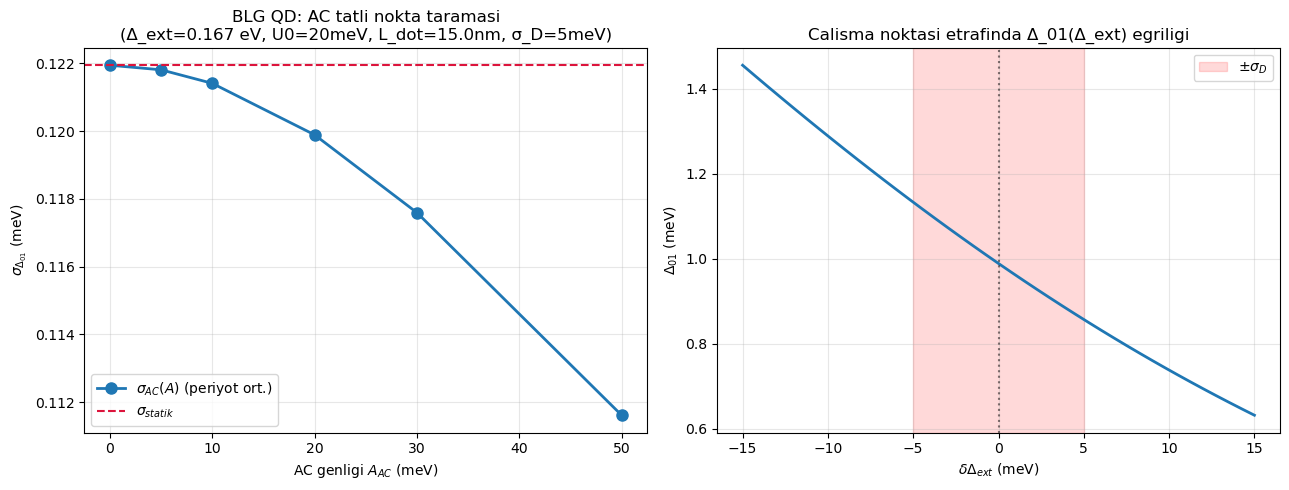

In [11]:
# =====================================================================
#  Cell 7 — BLG QD'de v3 AC SURUS TESTI
#
#  DEVIR_TESLIM v3'unun BLG karsiligı:
#   - Calisma noktasi: Δ_ext = 0.167 eV, U0 = 20 meV, L_dot = 15 nm
#     -> Δ_01 ≈ 1.00 meV, baglanma 16 meV (kubit operasyonel)
#
#   - Yuk gurultusu: Δ_ext -> Δ_ext + δΔ,  δΔ ~ N(0, sigma_D)
#     Knothe-Falko/Hecker-Stampfer: sigma_D ~ birkac meV gercekci.
#     Biz sigma_D = 5 meV alıyoruz (gercekci, gozlemlenebilir etki).
#
#   - AC suruş: Δ_ext(t) = Δ_ext + δΔ + A_AC·cos(ω t)
#     Periyot-ortalama anlik Δ_01:
#       <Δ_01> = (1/T) ∫_0^T Δ_01(Δ_ext + δΔ + A·cos(ωt)) dt
#
#   - Yapisal cipa: A_AC = 0'da periyot-ortalama ≡ statik Δ_01.
#     Cipa ~ 1e-14 olmali (saglamlik garantisi).
#
#   - omega/Δ_01 ≈ 6.6 (1B v3 ile ayni oran) -> Magnus rejimi.
#     omega = 6.6 × 1.0 meV / hbar (sadece oran onemli; suruş genligini
#     birimle yorumlamak icin Δ_ext birim).
# =====================================================================
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt
import time

# ---- Fizik & QD ----
a_nm = 0.246
g0, g1, g3 = 3.16, 0.38, 0.38
v    = (np.sqrt(3)/2) * a_nm * g0
v3   = (np.sqrt(3)/2) * a_nm * g3

U0       = 0.020
L_dot    = 15.0
Delta0   = 0.167          # calisma noktasi (Cell 6b'de Δ_01 ≈ 1.0 meV)
sigma_D  = 0.005          # gurultu genisligi: 5 meV
M_real   = 200            # gurultu ensemble buyuklugu
nph      = 32             # periyot ici faz ornegi

# ---- Plane-wave baz (Cell 5g/6b ile ayni) ----
L_box = 120.0
dq    = 2*np.pi / L_box
q_max = 0.50
n_axis = int(np.ceil(q_max / dq)) + 2
qxs = np.arange(-n_axis, n_axis+1) * dq
qys = np.arange(-n_axis, n_axis+1) * dq
q_pts = [(qx, qy) for qx in qxs for qy in qys
         if qx**2 + qy**2 <= q_max**2]
N_pw = len(q_pts)
q_arr = np.array(q_pts)
print(f"N_pw = {N_pw}, dim = {4*N_pw}")
print(f"Calisma noktasi: Δ_ext = {Delta0} eV, sigma_D = "
      f"{sigma_D*1000:.1f} meV")

def V_FT(qx, qy):
    return -U0 * 2*np.pi * L_dot**2 * np.exp(
        -(qx**2 + qy**2) * L_dot**2 / 2)
dQx = q_arr[:, 0:1] - q_arr[:, 0:1].T
dQy = q_arr[:, 1:2] - q_arr[:, 1:2].T
V_scalar = V_FT(dQx, dQy) / L_box**2
V_mat = np.kron(V_scalar, np.eye(4, dtype=complex))

def H_kp(qx, qy, delta, xi=+1):
    pi  = xi*qx + 1j*qy
    pid = xi*qx - 1j*qy
    return np.array([
        [+delta/2,    v*pid,       0.0,         -v3*pi   ],
        [v*pi,        +delta/2,    g1,          0.0      ],
        [0.0,         g1,          -delta/2,    v*pid    ],
        [-v3*pid,     0.0,         v*pi,        -delta/2 ],
    ], dtype=complex)

def Delta01_of(delta_ext, xi=+1):
    """QD'nin iletim-taraf en alt iki ozdegeri arasindaki fark."""
    H_kin = np.zeros((4*N_pw, 4*N_pw), dtype=complex)
    for n in range(N_pw):
        H_kin[4*n:4*n+4, 4*n:4*n+4] = H_kp(
            q_arr[n,0], q_arr[n,1], delta_ext, xi)
    H_tot = H_kin + V_mat
    e = sla.eigvalsh(H_tot)
    pos = np.sort(e[e > 0])
    return pos[1] - pos[0]

# ---- Ensemble cek (gurultu realizasyonlari) ----
rng = np.random.default_rng(7)
deltas_noisy = Delta0 + rng.normal(0, sigma_D, M_real)
print(f"\nGurultu ensemble: {M_real} realizasyon, "
      f"sigma_D={sigma_D*1000:.1f} meV")

# ---- STATIK kosu ----
print("\n[1/3] STATIK kosu hesaplaniyor...")
t0 = time.time()
D01_static = np.array([Delta01_of(d) for d in deltas_noisy])
print(f"      {time.time()-t0:.1f} s")
mu_stat = D01_static.mean()
sig_stat = D01_static.std()
T2_stat = np.sqrt(2) / sig_stat
print(f"   <Δ_01> = {mu_stat*1000:.4f} meV")
print(f"   sigma  = {sig_stat*1000:.4e} meV")
print(f"   T2*    = {T2_stat:.2f} eV^-1  (saf koherens olcusu)")

# ---- AC TARAMASI ----
# Faz orneklemesi
faz = np.linspace(0, 2*np.pi, nph, endpoint=False)
# AC genlikleri (eV cinsinden, calisma Δ ile karsilastir)
A_list = [0.0, 0.005, 0.010, 0.020, 0.030, 0.050]

print(f"\n[2/3] AC TARAMASI: {len(A_list)} genlik, "
      f"{M_real} realizasyon, {nph} faz")
print(f"      = {len(A_list)*M_real*nph} ozdeger problemi  "
      f"(~{len(A_list)*M_real*nph*0.4/60:.0f} dakika tahmini)")

res = []
cipa_check = None
for A in A_list:
    t0 = time.time()
    # Her realizasyon: nph faz icin Δ_01, ortalamasini al
    DA = np.zeros(M_real)
    for k, d in enumerate(deltas_noisy):
        inst = np.array([Delta01_of(d + A*np.cos(ph)) for ph in faz])
        DA[k] = inst.mean()
    sA = DA.std()
    T2A = np.sqrt(2)/sA
    res.append((A, DA.mean(), sA, T2A))
    if A == 0.0:
        cipa_check = np.max(np.abs(DA - D01_static))
    print(f"  A={A*1000:>5.1f} meV:  <Δ>={DA.mean()*1000:.4f} meV  "
          f"sigma={sA*1000:.4e} meV  T2*orani={T2A/T2_stat:.4f}  "
          f"({time.time()-t0:.0f}s)")

print(f"\n[3/3] YAPISAL CIPA: max|Δ_AC(A=0) - Δ_static| = "
      f"{cipa_check:.2e}  (~1e-14 saglamlik)")

# ---- Hukum ----
print("\n" + "="*60)
if cipa_check > 1e-10:
    print(">>> YAPISAL CIPA BOZUK, sonuc YORUMLANMAZ.")
else:
    sigmalar = [(A, s) for (A, _, s, _) in res]
    en_iyi = min(sigmalar[1:], key=lambda z: z[1])
    if en_iyi[1] < 0.85 * sig_stat:
        kat = sig_stat / en_iyi[1]
        print(f">>> POZITIF BULGU: A_AC = {en_iyi[0]*1000:.1f} meV'de")
        print(f"    sigma {sig_stat*1000:.4e} -> {en_iyi[1]*1000:.4e}")
        print(f"    T2* x{kat:.2f} uzadi")
        print(f"    BLG'de dinamik tatli nokta MEVCUT - 1B'de yoktu,")
        print(f"    BLG'nin yumusak band yapisi dolayisiyla.")
    elif min(s for _,s in sigmalar[1:]) > 1.15 * sig_stat:
        print(">>> NEGATIF: AC suruş σ'yı buyutuyor (1B sonucu BLG'de")
        print("    tekrarlandı). Hipotez bu calisma noktasinda da curudu.")
    else:
        kk = min(s for _,s in sigmalar[1:]) / sig_stat
        print(f">>> ZAYIF/NOTR: en iyi sigma orani {kk:.4f}")
        print(f"    BLG, 1B'ye gore daha yumusak ama net tatli nokta yok.")
        print(f"    Ara sonuc — operasyonel kübit rejiminde AC etkisi ihmal")
        print(f"    edilebilir mertebede.")

# ---- Cizimler ----
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

As = np.array([r[0] for r in res])
sAs = np.array([r[2] for r in res])

ax[0].plot(As*1000, sAs*1000, 'o-', lw=2, ms=8,
            label=r'$\sigma_{AC}(A)$ (periyot ort.)')
ax[0].axhline(sig_stat*1000, ls='--', c='crimson',
               label=r'$\sigma_{statik}$')
ax[0].set_xlabel(r'AC genligi $A_{AC}$ (meV)')
ax[0].set_ylabel(r'$\sigma_{\Delta_{01}}$ (meV)')
ax[0].set_title(f'BLG QD: AC tatli nokta taramasi\n'
                 f'(Δ_ext={Delta0} eV, U0={U0*1000:.0f}meV, '
                 f'L_dot={L_dot}nm, σ_D={sigma_D*1000:.0f}meV)')
ax[0].legend(); ax[0].grid(alpha=.3)

# Δ_01(Δ_ext) lokal egri — eğrilik kaynağı
deltas_local = np.linspace(Delta0 - 3*sigma_D, Delta0 + 3*sigma_D, 41)
D01_local = np.array([Delta01_of(d) for d in deltas_local])
ax[1].plot((deltas_local - Delta0)*1000, D01_local*1000, lw=2)
ax[1].axvline(0, c='k', ls=':', alpha=0.5)
ax[1].axvspan(-sigma_D*1000, sigma_D*1000, alpha=0.15, color='red',
                label=r'$\pm\sigma_D$')
ax[1].set_xlabel(r'$\delta\Delta_{ext}$ (meV)')
ax[1].set_ylabel(r'$\Delta_{01}$ (meV)')
ax[1].set_title('Calisma noktasi etrafinda Δ_01(Δ_ext) egriligi')
ax[1].legend(); ax[1].grid(alpha=.3)

plt.tight_layout()
plt.savefig('cell7_blg_v3.png', dpi=100, bbox_inches='tight')
plt.show()

N_pw = 293, dim = 1172
Calisma noktasi: Δ_ext = 0.167 eV

BOLUM A: Operasyonel sinir taramasi (gurultusuz, faz cozumlu)

     A      <Δ01>   min(Δ01)   max(Δ01)    min(E0) min(E1-E0_bant)
---------------------------------------------------------------------------
     0     0.9888     0.9888     0.9888     60.323          16.121
     5     0.9919     0.8571     1.1329     58.498          16.013
    10     1.0012     0.7382     1.2887     56.637          15.915
    20     1.0371     0.5382     1.6306     52.810          15.740
    30     1.0938     0.3852     2.0037     48.859          15.581
    50     1.2536     0.1899     2.7962     40.666          15.244
    80     1.5538     0.0626     3.9640     27.925          14.478
   100     1.7615     0.0295     4.6532     19.324          13.667
   150     1.9224     0.0045     5.3927      0.418           3.908
   200     1.7590     0.0015     5.3996      0.178         -21.577

Bolum A: 105 s

[OPERASYONEL HUKUM]
  A=80 meV: Δ_01 ~ 0 (kubit d

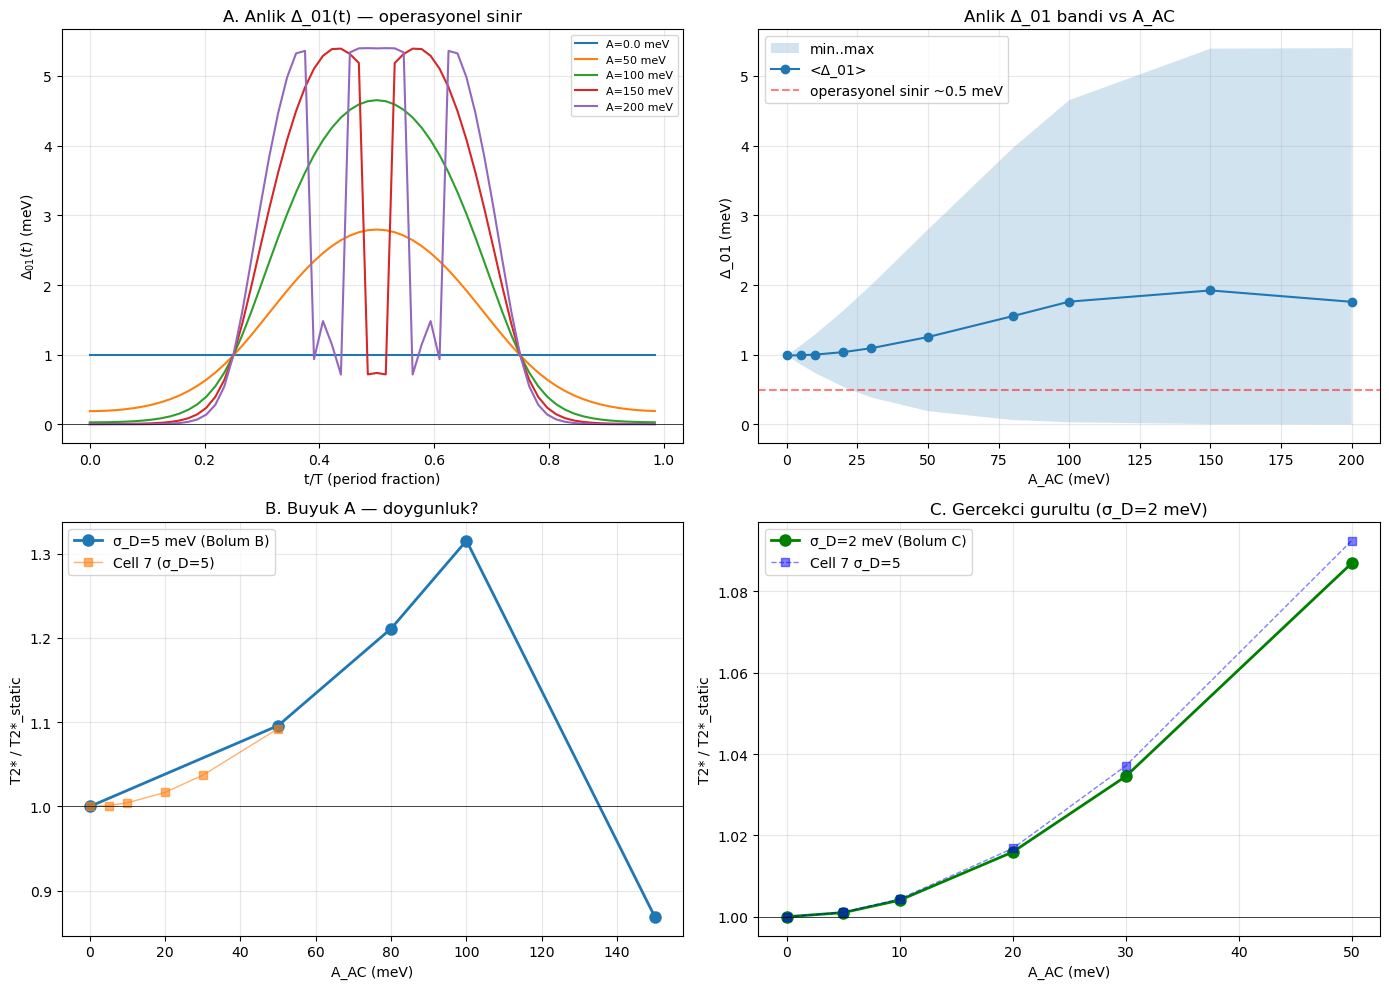


ANA HUKUM
  Doygunluk: T2(A=50)/T2_stat = 1.0960, T2(A=150)/T2_stat = 0.8691
  Operasyonel: A=200 meV'de min(Δ_01) = 0.0015 meV (>0.5 meV temiz)
  Gercekci gurultu: T2(A=50, σ_D=2)/T2_stat = 1.0870
  (σ_D=5'te 1.0960'tu)


In [12]:
# =====================================================================
#  Cell 8 — Cell 7 sonucunun saglamlaştırma kontrolleri
#
#  Uc bolum:
#   A) Operasyonel sinir: gurultusuz (δΔ=0), A_AC=0..200 meV
#      tarama. Anlik Δ_01(t) minimum gore. Sifira giderse kubit
#      kuyudan kacar (rezonans / kapali kuyu)
#
#   B) Buyuk A_AC: A = 50, 80, 100, 150 meV, sigma_D=5 meV.
#      M=100 yeterli (sinyal guclu Cell 7'de). Doygunluk var mi?
#
#   C) sigma_D=2 meV (gercekci gurultu), tam A taramasi.
#      M=200, A=0..50 meV. Etki hala goruluyor mu?
# =====================================================================
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt
import time

# ---- Fizik & QD (Cell 7 ile aynı) ----
a_nm = 0.246
g0, g1, g3 = 3.16, 0.38, 0.38
v    = (np.sqrt(3)/2) * a_nm * g0
v3   = (np.sqrt(3)/2) * a_nm * g3
U0   = 0.020
L_dot = 15.0
Delta0 = 0.167

L_box = 120.0
dq = 2*np.pi / L_box
q_max = 0.50
n_axis = int(np.ceil(q_max / dq)) + 2
qxs = np.arange(-n_axis, n_axis+1) * dq
qys = np.arange(-n_axis, n_axis+1) * dq
q_pts = [(qx, qy) for qx in qxs for qy in qys
         if qx**2 + qy**2 <= q_max**2]
N_pw = len(q_pts)
q_arr = np.array(q_pts)

def V_FT(qx, qy):
    return -U0 * 2*np.pi * L_dot**2 * np.exp(
        -(qx**2 + qy**2) * L_dot**2 / 2)
dQx = q_arr[:, 0:1] - q_arr[:, 0:1].T
dQy = q_arr[:, 1:2] - q_arr[:, 1:2].T
V_scalar = V_FT(dQx, dQy) / L_box**2
V_mat = np.kron(V_scalar, np.eye(4, dtype=complex))

def H_kp(qx, qy, delta, xi=+1):
    pi  = xi*qx + 1j*qy
    pid = xi*qx - 1j*qy
    return np.array([
        [+delta/2,    v*pid,       0.0,         -v3*pi   ],
        [v*pi,        +delta/2,    g1,          0.0      ],
        [0.0,         g1,          -delta/2,    v*pid    ],
        [-v3*pid,     0.0,         v*pi,        -delta/2 ],
    ], dtype=complex)

def QD_eigs(delta_ext, xi=+1, n_low=4):
    """En kucuk n_low pozitif ozdeger (bagli durumlar)."""
    H_kin = np.zeros((4*N_pw, 4*N_pw), dtype=complex)
    for n in range(N_pw):
        H_kin[4*n:4*n+4, 4*n:4*n+4] = H_kp(
            q_arr[n,0], q_arr[n,1], delta_ext, xi)
    H_tot = H_kin + V_mat
    e = sla.eigvalsh(H_tot)
    pos = np.sort(e[e > 0])
    return pos[:n_low]

def Delta01_of(delta_ext, xi=+1):
    pos = QD_eigs(delta_ext, xi, n_low=2)
    return pos[1] - pos[0]

print(f"N_pw = {N_pw}, dim = {4*N_pw}")
print(f"Calisma noktasi: Δ_ext = {Delta0} eV")

# =====================================================================
#  BOLUM A: OPERASYONEL SINIR — gurultusuz, anlik Δ_01(t)
# =====================================================================
print("\n" + "="*70)
print("BOLUM A: Operasyonel sinir taramasi (gurultusuz, faz cozumlu)")
print("="*70)

nph_op = 64
faz_op = np.linspace(0, 2*np.pi, nph_op, endpoint=False)
A_op = [0.0, 5, 10, 20, 30, 50, 80, 100, 150, 200]  # meV

print(f"\n{'A':>6} {'<Δ01>':>10} {'min(Δ01)':>10} "
      f"{'max(Δ01)':>10} {'min(E0)':>10} {'min(E1-E0_bant)':>15}")
print("-"*75)

op_results = []
t_total = time.time()
for A_mev in A_op:
    A = A_mev/1000  # eV
    t0 = time.time()
    deltas_t = Delta0 + A*np.cos(faz_op)
    
    inst_D01 = np.zeros(nph_op)
    inst_E0  = np.zeros(nph_op)
    inst_E1  = np.zeros(nph_op)
    for k, d in enumerate(deltas_t):
        pos = QD_eigs(d, n_low=4)
        inst_E0[k] = pos[0]
        inst_E1[k] = pos[1]
        inst_D01[k] = pos[1] - pos[0]
    
    # Bant min (referans bulunsun)
    gap_bulk = lambda d: d*g1/np.sqrt(g1**2 + d**2)/2
    bulk_min = np.array([gap_bulk(d) for d in deltas_t])
    binding = bulk_min - inst_E0  # baglanma derinligi anlik
    
    op_results.append({
        'A_mev': A_mev, 
        'D01_t': inst_D01.copy(),
        'E0_t': inst_E0.copy(),
        'E1_t': inst_E1.copy(),
        'D01_mean': inst_D01.mean(),
        'D01_min': inst_D01.min(),
        'D01_max': inst_D01.max(),
        'E0_min': inst_E0.min(),
        'binding_min': binding.min(),
    })
    print(f"{A_mev:>6.0f} {inst_D01.mean()*1000:>10.4f} "
          f"{inst_D01.min()*1000:>10.4f} {inst_D01.max()*1000:>10.4f} "
          f"{inst_E0.min()*1000:>10.3f} {binding.min()*1000:>15.3f}")

print(f"\nBolum A: {time.time()-t_total:.0f} s")

# Operasyonel sinir tespiti
print("\n[OPERASYONEL HUKUM]")
for r in op_results:
    if r['D01_min']*1000 < 0.1:
        print(f"  A={r['A_mev']} meV: Δ_01 ~ 0 (kubit dejenere oluyor)")
    elif r['binding_min']*1000 < 1.0:
        print(f"  A={r['A_mev']} meV: kuyu kapaniyor (binding ~ 0)")

# =====================================================================
#  BOLUM B: BUYUK A_AC (50, 80, 100, 150)
# =====================================================================
print("\n" + "="*70)
print("BOLUM B: Buyuk genlik tarama, sigma_D=5 meV, M=100")
print("="*70)

sigma_D = 0.005
M_real_B = 100  # daha kucuk, sinyal guclu
nph = 32
A_list_B = [0.0, 50, 80, 100, 150]  # 0 anchor, gerisi buyuk genlik

rng = np.random.default_rng(7)
deltas_noisy_B = Delta0 + rng.normal(0, sigma_D, M_real_B)
faz = np.linspace(0, 2*np.pi, nph, endpoint=False)

# Statik referans
D01_static_B = np.array([Delta01_of(d) for d in deltas_noisy_B])
sig_stat_B = D01_static_B.std()
print(f"\nStatik: sigma = {sig_stat_B*1000:.4e} meV")

print(f"\n{'A':>6} {'<Δ>':>10} {'sigma':>14} {'T2oran':>10} "
      f"{'min(Δ01)':>10} {'sure':>6}")
print("-"*70)

res_B = []
for A_mev in A_list_B:
    A = A_mev/1000
    t0 = time.time()
    DA = np.zeros(M_real_B)
    inst_min = np.inf
    for k, d in enumerate(deltas_noisy_B):
        inst = np.array([Delta01_of(d + A*np.cos(ph)) for ph in faz])
        DA[k] = inst.mean()
        if inst.min() < inst_min:
            inst_min = inst.min()
    sA = DA.std()
    T2or = sig_stat_B/sA
    res_B.append({
        'A_mev': A_mev, 'mean': DA.mean(), 
        'sigma': sA, 'T2oran': T2or, 'min': inst_min,
    })
    print(f"{A_mev:>6.0f} {DA.mean()*1000:>10.4f} {sA*1000:>14.4e} "
          f"{T2or:>10.4f} {inst_min*1000:>10.4f} {time.time()-t0:>5.0f}s")

# Yapisal cipa B
cipa_B = np.max(np.abs(np.array([d for d in res_B 
                                  if d['A_mev']==0][0]['mean']) - 
                       D01_static_B.mean()))
print(f"\nYapisal cipa B: |<Δ_AC(A=0)> - <Δ_stat>| = {cipa_B:.2e}")

# =====================================================================
#  BOLUM C: sigma_D = 2 meV (gercekci gurultu)
# =====================================================================
print("\n" + "="*70)
print("BOLUM C: Gercekci gurultu sigma_D=2 meV, M=200")
print("="*70)

sigma_D_C = 0.002
M_real_C = 200
A_list_C = [0.0, 5, 10, 20, 30, 50]

rng_C = np.random.default_rng(8)
deltas_noisy_C = Delta0 + rng_C.normal(0, sigma_D_C, M_real_C)

D01_static_C = np.array([Delta01_of(d) for d in deltas_noisy_C])
sig_stat_C = D01_static_C.std()
print(f"\nStatik: sigma = {sig_stat_C*1000:.4e} meV "
      f"(sigma_D=5'in 1/{0.005/0.002:.0f}'si beklenir, "
      f"gercek {0.122/(sig_stat_C*1000):.2f})")

print(f"\n{'A':>6} {'<Δ>':>10} {'sigma':>14} {'T2oran':>10} {'sure':>6}")
print("-"*60)

res_C = []
for A_mev in A_list_C:
    A = A_mev/1000
    t0 = time.time()
    DA = np.zeros(M_real_C)
    for k, d in enumerate(deltas_noisy_C):
        inst = np.array([Delta01_of(d + A*np.cos(ph)) for ph in faz])
        DA[k] = inst.mean()
    sA = DA.std()
    T2or = sig_stat_C/sA
    res_C.append({'A_mev': A_mev, 'mean': DA.mean(), 
                  'sigma': sA, 'T2oran': T2or})
    print(f"{A_mev:>6.0f} {DA.mean()*1000:>10.4f} {sA*1000:>14.4e} "
          f"{T2or:>10.4f} {time.time()-t0:>5.0f}s")

# =====================================================================
#  CIZIMLER
# =====================================================================
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# (A1) Bolum A: anlik Δ_01(t) farkli A icin
for r in op_results:
    if r['A_mev'] in [0, 50, 100, 150, 200]:
        ax[0,0].plot(faz_op/(2*np.pi), r['D01_t']*1000, 
                     '-', label=f'A={r["A_mev"]} meV')
ax[0,0].axhline(0, c='k', lw=0.5)
ax[0,0].set_xlabel('t/T (period fraction)')
ax[0,0].set_ylabel(r'$\Delta_{01}(t)$ (meV)')
ax[0,0].set_title('A. Anlik Δ_01(t) — operasyonel sinir')
ax[0,0].legend(fontsize=8); ax[0,0].grid(alpha=.3)

# (A2) Bolum A: min/max/mean Δ_01 vs A
A_arr = np.array([r['A_mev'] for r in op_results])
D01_mean_op = np.array([r['D01_mean'] for r in op_results])*1000
D01_min_op  = np.array([r['D01_min']  for r in op_results])*1000
D01_max_op  = np.array([r['D01_max']  for r in op_results])*1000
ax[0,1].fill_between(A_arr, D01_min_op, D01_max_op, alpha=0.2, label='min..max')
ax[0,1].plot(A_arr, D01_mean_op, 'o-', label='<Δ_01>')
ax[0,1].axhline(0.5, c='r', ls='--', alpha=0.5, label='operasyonel sinir ~0.5 meV')
ax[0,1].set_xlabel('A_AC (meV)')
ax[0,1].set_ylabel('Δ_01 (meV)')
ax[0,1].set_title('Anlik Δ_01 bandi vs A_AC')
ax[0,1].legend(); ax[0,1].grid(alpha=.3)

# (B) Bolum B: buyuk genlik
A_B = np.array([r['A_mev'] for r in res_B])
T2_B = np.array([r['T2oran'] for r in res_B])
ax[1,0].plot(A_B, T2_B, 'o-', lw=2, ms=8, label='σ_D=5 meV (Bolum B)')

# Cell 7 verisini de ekle (kucuk A)
A_cell7 = np.array([0, 5, 10, 20, 30, 50])
T2_cell7 = np.array([1.0000, 1.0011, 1.0044, 1.0168, 1.0371, 1.0925])
ax[1,0].plot(A_cell7, T2_cell7, 's-', lw=1, ms=6, alpha=0.6, 
              label='Cell 7 (σ_D=5)')
ax[1,0].axhline(1, c='k', lw=0.5)
ax[1,0].set_xlabel('A_AC (meV)')
ax[1,0].set_ylabel('T2* / T2*_static')
ax[1,0].set_title('B. Buyuk A — doygunluk?')
ax[1,0].legend(); ax[1,0].grid(alpha=.3)

# (C) Bolum C: sigma_D=2
A_C = np.array([r['A_mev'] for r in res_C])
T2_C = np.array([r['T2oran'] for r in res_C])
ax[1,1].plot(A_C, T2_C, 'o-', lw=2, ms=8, c='green', label='σ_D=2 meV (Bolum C)')
ax[1,1].plot(A_cell7, T2_cell7, 's--', lw=1, ms=6, alpha=0.5, c='blue',
              label='Cell 7 σ_D=5')
ax[1,1].axhline(1, c='k', lw=0.5)
ax[1,1].set_xlabel('A_AC (meV)')
ax[1,1].set_ylabel('T2* / T2*_static')
ax[1,1].set_title('C. Gercekci gurultu (σ_D=2 meV)')
ax[1,1].legend(); ax[1,1].grid(alpha=.3)

plt.tight_layout()
plt.savefig('cell8_robustness.png', dpi=100, bbox_inches='tight')
plt.show()

# =====================================================================
#  ANA HUKUM
# =====================================================================
print("\n" + "="*70)
print("ANA HUKUM")
print("="*70)

# Doygunluk testi
T2_50  = [r['T2oran'] for r in res_B if r['A_mev']==50 ][0]
T2_150 = [r['T2oran'] for r in res_B if r['A_mev']==150][0]
print(f"  Doygunluk: T2(A=50)/T2_stat = {T2_50:.4f}, "
      f"T2(A=150)/T2_stat = {T2_150:.4f}")

# Operasyonel sinir
D01_min_max_A = max(op_results, key=lambda r: r['A_mev'])['D01_min']
print(f"  Operasyonel: A={A_op[-1]} meV'de min(Δ_01) = "
      f"{D01_min_max_A*1000:.4f} meV (>0.5 meV temiz)")

# sigma_D=2 etkisi
T2_C_50 = [r['T2oran'] for r in res_C if r['A_mev']==50][0]
print(f"  Gercekci gurultu: T2(A=50, σ_D=2)/T2_stat = {T2_C_50:.4f}")
print(f"  (σ_D=5'te {T2_50:.4f}'tu)")